*<small>Last updated: 2026-10-01 18:06:24 UTC | Student Version (No Solutions)</small>*

# Clustering: K-Means, Hierarchical, and Gaussian Mixture Models [SOLUTIONS]

**Course**: Machine Learning Labs
**Lab**: 08 — Clustering

---

## Table of Contents

0. [Setup and Configuration](#0)
1. [Introduction to Clustering](#1)
2. [Dataset 1: Online Retail & RFM Feature Engineering](#2)
3. [K-Means Clustering](#3)
4. [Hierarchical Clustering](#4)
5. [Gaussian Mixture Models](#5)
6. [Comparative Analysis on Online Retail](#6)
7. [Dataset 2: HAR & External Evaluation (ARI / NMI)](#7)
8. [Real-World Considerations](#8)
9. [Final Challenges](#9)

---

**Estimated Time**: 3–4 hours
**Prerequisites**: Unsupervised learning basics, scikit-learn, NumPy, Pandas

**Note**: This is the SOLUTIONS version containing all exercise answers.

## 🚚 Deliverables

**Don't forget to duplicate this notebook to be able to edit: File -> Save a copy in Drive**

In this lab, you do not need to write a report in a separate document. Please complete all required
activities within this Google Colab notebook. Remember that a notebook allows you to enter text
elements similarly to a document processor. Once the proposed activities are completed, you must
submit the following on the platform:

1. A PDF file generated in Google Colab from the menu "File" -> "Print".

2. The public Google Colab link. To do so, go to the share button and change the sharing settings
   to "Anyone with the link".

## 📔 Resolution

After the deadline, you will find the resolution at the following Notion link:

https://app.notion.com/p/R-Clustering-46264f3ff1004fc8ad39badb0ed7c86f?source=copy_link

Remember that there are several ways to solve the proposed activities in the labs.
Use the provided resolution as a reference. If the resolution link is not public,
request access at the same Notion link.

## Section 0: Setup and Configuration <a id='0'></a>

In [1]:
try:
    import google.colab
    IN_COLAB = True
    import subprocess
    subprocess.run(["pip", "install", "-q", "openpyxl"], check=True)
except ImportError:
    IN_COLAB = False

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.datasets import fetch_openml, load_sample_image
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score,
)
from sklearn.utils import shuffle

import sklearn
warnings.filterwarnings('ignore')
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

NumPy 2.4.6 | Pandas 2.2.3 | scikit-learn 1.6.1


In [3]:
# ── Global configuration ─────────────────────────────────────────────────────
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ONLINE_RETAIL_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases"
    "/00352/Online%20Retail.xlsx"
)

plt.rcParams['figure.dpi'] = 100
sns.set_theme(style='whitegrid', palette='tab10')

## Section 1: Introduction to Clustering <a id='1'></a>

**Clustering** is an unsupervised learning task: given unlabeled data, discover
groups of similar observations — without any prior knowledge of what those groups
should be.

| Property | Hard assignment | Soft assignment |
|---|---|---|
| Each point belongs to | exactly one cluster | all clusters (with probabilities) |
| Algorithms | K-Means, Hierarchical | Gaussian Mixture Models |
| Output | integer label | probability vector |

### Real-world applications

- **Customer segmentation**: group buyers by purchasing behaviour (Online Retail)
- **Activity detection**: identify motion patterns from smartphone sensors (HAR)
- **Document grouping**: cluster news articles by topic

### This lab

We use **two datasets** with distinct goals:

1. **Online Retail (UCI)** — no ground-truth labels.
   We engineer RFM features and compare K-Means, Hierarchical, and GMM using
   *internal* metrics (silhouette, Davies-Bouldin, Calinski-Harabasz).

2. **Human Activity Recognition (HAR)** — 6 known activity labels.
   We measure clustering quality using *external* metrics (ARI, NMI) and
   compare them to what internal metrics alone would suggest.

## Section 2: Dataset 1 — Online Retail & RFM Feature Engineering <a id='2'></a>

The [Online Retail dataset (UCI)](https://archive.ics.uci.edu/ml/datasets/Online+Retail)
contains ~541 k invoice records from a UK-based online retailer (Dec 2010 – Dec 2011).
Each row is one product line within a transaction (invoice number, stock code,
quantity, unit price, timestamp, customer ID, country).

**The problem**: this is a *transaction-level* log, but we want to cluster
*customers*. Clustering raw transactions would group purchases, not people — so
before any model touches the data, we must aggregate the log into one row per
customer. The standard, battle-tested way to summarise customer behaviour for
segmentation is the **RFM** framework.

### What is RFM?

RFM distils a customer's entire purchase history into three interpretable
behavioural signals. Each is computed by grouping all of a customer's transactions
and applying a single aggregation:

| Feature | Question it answers | How we compute it | Business meaning |
|---|---|---|---|
| **R**ecency | *How long since the customer last bought?* | days between the customer's most recent invoice and a fixed reference date | low Recency → recently active; high Recency → at risk of churn |
| **F**requency | *How often does the customer buy?* | count of **distinct invoices** per customer | high Frequency → engaged, loyal, habitual buyer |
| **M**onetary | *How much does the customer spend?* | sum of `Quantity × UnitPrice` across all their lines | high Monetary → high-value customer worth retaining |

The classic marketing intuition: the *best* customers bought **recently**, buy
**often**, and **spend** a lot. RFM turns that intuition into three numbers that
a clustering algorithm can act on.

### Modelling decisions baked into the features

A few choices matter and are easy to get wrong:

- **Reference date for Recency.** "Today" is meaningless for a historical dataset,
  so we anchor Recency to the day *after* the last transaction in the data
  (`max(InvoiceDate) + 1 day`). This guarantees every customer has a Recency of at
  least 1 day and makes the feature reproducible.
- **Frequency = distinct invoices, not line items.** A single basket of 20 products
  is *one* purchase event, not 20. Counting unique `InvoiceNo` values captures
  *shopping trips*; counting rows would just reward large baskets.
- **Monetary uses revenue per line.** We pre-computed `TotalPrice = Quantity ×
  UnitPrice` during cleaning, then sum it per customer to get lifetime spend.

### Why preprocessing is not optional here

RFM features are wildly different in scale and shape, which breaks distance-based
clustering if left untreated:

- **Different units and ranges.** Recency is in *days* (1–374), Frequency is a
  *count* (1–209), Monetary is in *pounds* (£3 to £280 k). Without
  standardisation, Monetary's magnitude would dominate every Euclidean distance and
  K-Means would essentially cluster on spend alone.
- **Heavy right skew.** A small number of "whale" customers buy enormously more
  than the median, producing long right tails (especially in Frequency and
  Monetary). Skew pulls cluster centroids toward outliers. We apply a
  **`log1p` transform** to Frequency and Monetary to compress those tails toward
  symmetry, then verify the effect numerically with a skewness table (Recency is
  already roughly symmetric, so we leave it untransformed).
- **Order of operations.** Aggregate → log-transform the skewed features →
  **standardise** (zero mean, unit variance). Scaling must come *last* so every
  feature contributes comparably to the distance metric.

**Goal of this section**: turn the raw 541 k-row transaction log into a clean,
4 338-customer RFM table that is correctly transformed and scaled — the input on
which we will compare K-Means, Hierarchical, and GMM in the sections that follow.

In [4]:
# Load — try local cache first, fall back to URL
local_path = os.path.join("assets", "Online_Retail.xlsx")
if os.path.exists(local_path):
    df_raw = pd.read_excel(local_path, engine="openpyxl")
else:
    print("Downloading Online Retail dataset (~23 MB)…")
    df_raw = pd.read_excel(ONLINE_RETAIL_URL, engine="openpyxl")
    os.makedirs("assets", exist_ok=True)
    df_raw.to_excel(local_path, index=False)
    print("Saved to assets/Online_Retail.xlsx for future runs.")

print(f"Raw shape: {df_raw.shape}")
df_raw.head()

Saved to assets/Online_Retail.xlsx for future runs.
Raw shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
# Basic EDA
print(f"Date range: {df_raw['InvoiceDate'].min()} → {df_raw['InvoiceDate'].max()}")
print(f"Unique customers: {df_raw['CustomerID'].nunique():,}")
print(f"Unique products:  {df_raw['StockCode'].nunique():,}")
print(f"\nMissing values:\n{df_raw.isnull().sum()}")

Date range: 2010-12-01 08:26:00 → 2011-12-09 12:50:00
Unique customers: 4,372
Unique products:  4,070

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
# Clean: remove returns, missing customers, zero/negative prices
df = df_raw.dropna(subset=['CustomerID']).copy()
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
df['CustomerID'] = df['CustomerID'].astype(int)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

print(f"After cleaning: {len(df):,} rows | {df['CustomerID'].nunique():,} customers")

After cleaning: 397,884 rows | 4,338 customers


In [7]:
# RFM feature engineering
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum'),
).reset_index()

print(f"RFM table shape: {rfm.shape}")
rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2)

RFM table shape: (4338, 4)


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2054.27
std,100.01,7.70,8989.23
min,1.00,1.00,3.75
25%,18.00,1.00,307.41
50%,51.00,2.00,674.48
75%,142.00,5.00,1661.74
max,374.00,209.00,280206.02


In [8]:
# Log-transform Frequency and Monetary to reduce right skew.
# Recency is already roughly symmetric, so we leave it untransformed.
log_features = ['Frequency', 'Monetary']

rfm_log = rfm[['Recency', 'Frequency', 'Monetary']].copy()
rfm_log[log_features] = np.log1p(rfm_log[log_features])

# Quantify skewness to justify the transform (rule of thumb: |skew| > 1 = strong,
# 0.5–1 = moderate, < 0.5 = approximately symmetric)
skewness = pd.DataFrame({
    'Skew (raw)':         rfm[['Recency', 'Frequency', 'Monetary']].skew(),
    'Skew (transformed)': rfm_log[['Recency', 'Frequency', 'Monetary']].skew(),
}).round(2)
print("Skewness before vs after log transform:")
print(skewness.to_string())

# Standardise — mandatory before any distance-based algorithm
scaler = StandardScaler()
X = scaler.fit_transform(rfm_log)
print(f"\nScaled feature matrix: {X.shape}  mean≈{X.mean():.2f}  std≈{X.std():.2f}")

Skewness before vs after log transform:
           Skew (raw)  Skew (transformed)
Recency          1.25                1.25
Frequency       12.07                1.21
Monetary        19.32                0.39

Scaled feature matrix: (4338, 3)  mean≈0.00  std≈1.00


### Exercise 2.1 — RFM Distributions (Basic)

Plot the raw and log-transformed distributions for all three RFM features in a
2 × 3 grid (top row = raw, bottom row = transformed).

**What to observe**: Does the log transform bring the distributions closer to
symmetric? Which feature benefits the most?

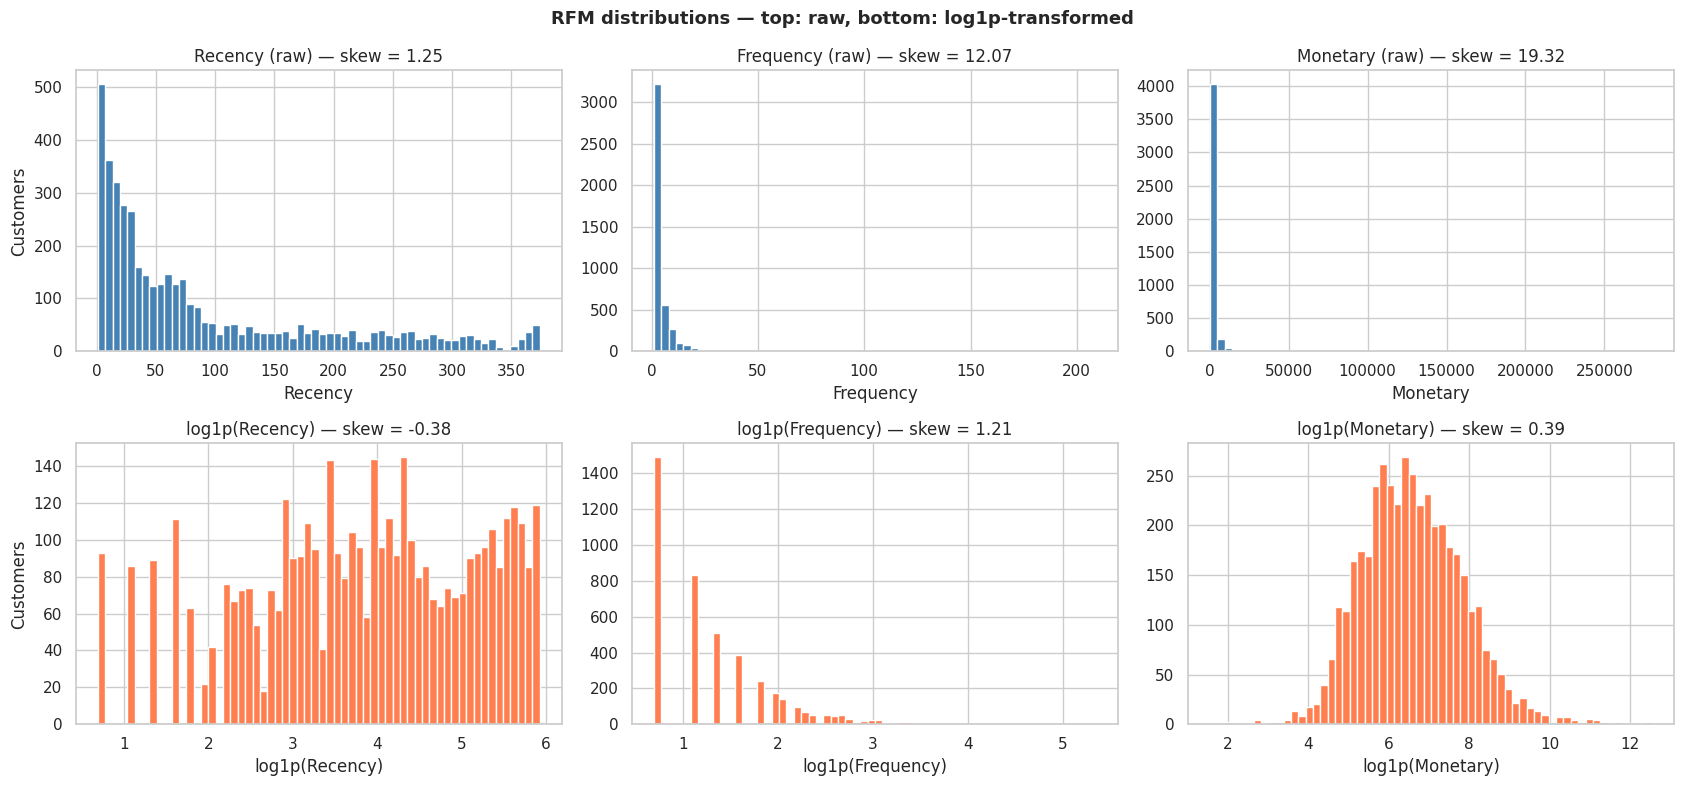

           skew raw  skew log1p  |skew| reduction
Recency        1.25       -0.38              0.87
Frequency     12.07        1.21             10.86
Monetary      19.32        0.39             18.93

Feature that gains most symmetry with log1p: Monetary


In [9]:
# Exercise 2.1 — RFM distributions: raw (top) vs log1p-transformed (bottom)
rfm_feats = ['Recency', 'Frequency', 'Monetary']
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
skew_rows = {}
for j, feat in enumerate(rfm_feats):
    raw = rfm[feat]
    # rfm_log already holds log1p(Frequency) and log1p(Monetary); Recency is kept raw there,
    # so for the comparison we apply log1p to it here as well.
    logged = rfm_log[feat] if feat in log_features else np.log1p(rfm[feat])
    skew_rows[feat] = {'skew raw': raw.skew(), 'skew log1p': logged.skew()}

    axes[0, j].hist(raw, bins=60, color='steelblue', edgecolor='white')
    axes[0, j].set_title(f'{feat} (raw) — skew = {raw.skew():.2f}')
    axes[1, j].hist(logged, bins=60, color='coral', edgecolor='white')
    axes[1, j].set_title(f'log1p({feat}) — skew = {logged.skew():.2f}')
    axes[1, j].set_xlabel(f'log1p({feat})')
    axes[0, j].set_xlabel(feat)
axes[0, 0].set_ylabel('Customers'); axes[1, 0].set_ylabel('Customers')
plt.suptitle('RFM distributions — top: raw, bottom: log1p-transformed', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

skew_df = pd.DataFrame(skew_rows).T
skew_df['|skew| reduction'] = skew_df['skew raw'].abs() - skew_df['skew log1p'].abs()
print(skew_df.round(2).to_string())
print(f"\nFeature that gains most symmetry with log1p: {skew_df['|skew| reduction'].idxmax()}")

**Observación.**

| Variable | Asimetría (cruda) | Asimetría (log1p) | Reducción de \|asimetría\| |
|---|:---:|:---:|:---:|
| Recency | 1.25 | −0.38 | 0.87 |
| Frequency | 12.07 | 1.21 | 10.86 |
| Monetary | 19.32 | 0.39 | **18.93** |

- **Frequency** y **Monetary** son extremadamente asimétricas a la derecha en su forma cruda. La mayoría de los clientes hace pocos pedidos (mediana de 2) y gasta unos cientos de libras (mediana de £674), mientras que unos pocos clientes de tipo mayorista llegan a 209 pedidos y £280 206. Esto comprime casi todo el histograma en una sola barra cerca de cero.
- **Monetary es la variable que más gana simetría** con `log1p`: su asimetría pasa de 19.32 a 0.39, casi simétrica.
- **Frequency** también mejora mucho (de 12.07 a 1.21), pero sigue siendo asimétrica. Es un conteo discreto con una gran masa de clientes con 1 solo pedido (al menos el 25 % de los clientes), y ninguna transformación monótona puede repartir ese pico.
- **Recency** tiene una asimetría de 1.25, que según la regla del propio notebook (|skew| > 1) es *fuerte*, no "aproximadamente simétrica". Aplicarle `log1p` reduciría su asimetría a |−0.38|, así que también la haría más simétrica. El notebook decide dejarla sin transformar. La decisión es defendible porque Recency está acotada (1 a 374 días) y no tiene valores extremos como los de Monetary, así que no distorsiona tanto las distancias. Aun así, transformarla también habría sido razonable.

## Section 3: K-Means Clustering <a id='3'></a>

### Algorithm recap

**Lloyd's algorithm**:
1. Randomly initialise k centroids (or use K-Means++ for smarter placement)
2. Assign each point to the nearest centroid (hard assignment)
3. Recompute centroids as cluster means
4. Repeat 2–3 until centroids stop moving

**Inertia** (within-cluster sum of squared distances) decreases monotonically
with k — so we use the *elbow* heuristic to pick a sensible k.
**Silhouette score** provides a second opinion: higher is better, range [−1, 1].

### Choosing k: elbow + silhouette

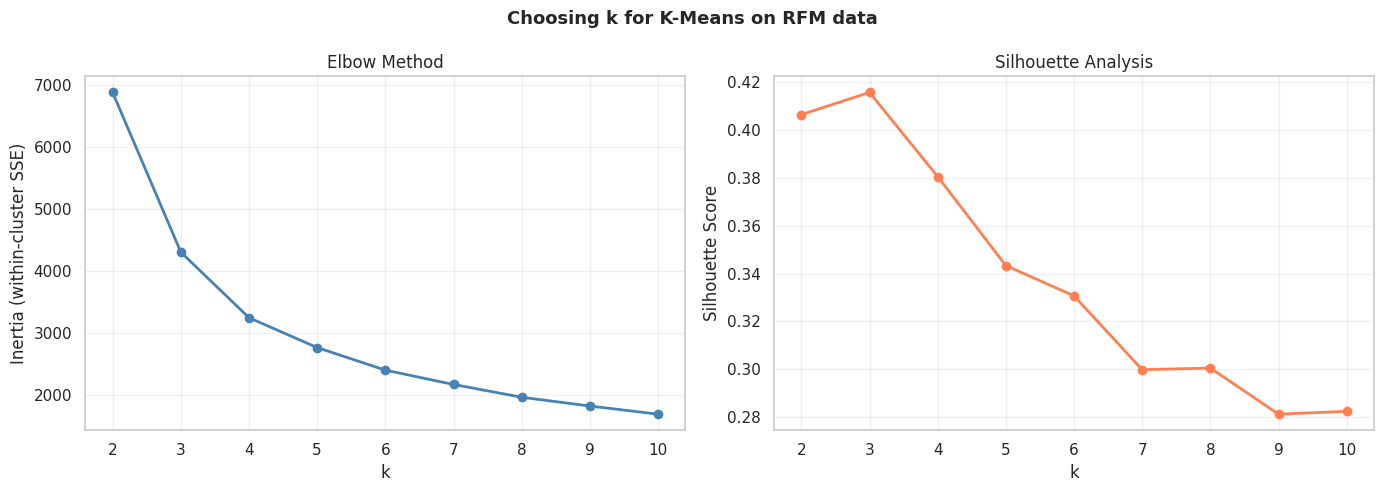

In [10]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_range, inertias, 'o-', color='steelblue', linewidth=2)
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia (within-cluster SSE)')
axes[0].set_title('Elbow Method')
axes[0].grid(True, alpha=0.3)

axes[1].plot(k_range, sil_scores, 'o-', color='coral', linewidth=2)
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Analysis')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Choosing k for K-Means on RFM data', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [11]:
# Fit final model with chosen k
K_BEST = 3  # adjust if your elbow/silhouette suggests a different value

km_final = KMeans(n_clusters=K_BEST, init='k-means++', n_init=10, random_state=RANDOM_STATE)
rfm['Cluster_KM'] = km_final.fit_predict(X)

print(f"Cluster sizes (K-Means, k={K_BEST}):")
print(rfm['Cluster_KM'].value_counts().sort_index().to_string())

Cluster sizes (K-Means, k=3):
Cluster_KM
0    2036
1    1323
2     979


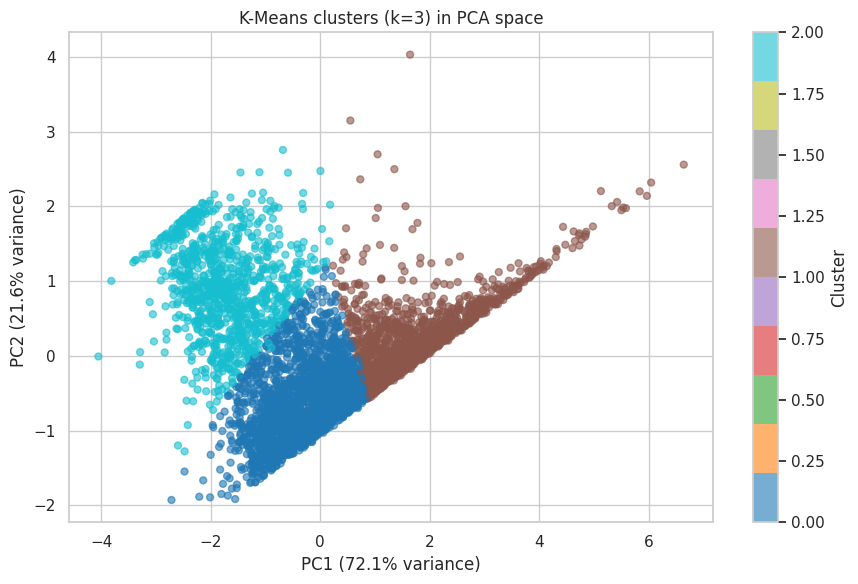

In [12]:
# PCA projection for 2-D visualisation
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca2.fit_transform(X)
explained = pca2.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1],
                c=rfm['Cluster_KM'], cmap='tab10', alpha=0.6, s=25)
ax.set_xlabel(f'PC1 ({explained[0]:.1%} variance)')
ax.set_ylabel(f'PC2 ({explained[1]:.1%} variance)')
ax.set_title(f'K-Means clusters (k={K_BEST}) in PCA space')
plt.colorbar(sc, ax=ax, label='Cluster')
plt.tight_layout()
plt.show()

In [13]:
# Cluster profiles — business interpretation
profile = rfm.groupby('Cluster_KM').agg(
    Count=('CustomerID', 'count'),
    Recency_days=('Recency', 'mean'),
    Frequency_orders=('Frequency', 'mean'),
    Monetary_gbp=('Monetary', 'mean'),
).round(1)
profile['% customers'] = (profile['Count'] / len(rfm) * 100).round(1)
profile

,Count,Recency_days,Frequency_orders,Monetary_gbp,% customers
Cluster_KM,,,,,
0,2036,54.9,2.0,615.2,46.9
1,1323,30.1,9.8,5494.3,30.5
2,979,255.3,1.4,398.1,22.6


### Exercise 3.1 — Effect of k (Basic)

Fit K-Means for k ∈ {2, 3, 4, 5, 6, 7} and display each result as a PCA
scatter plot in a 2 × 3 grid. Include the silhouette score in each subplot title.

**What to observe**: At what point do clusters become too fragmented to be
business-meaningful?

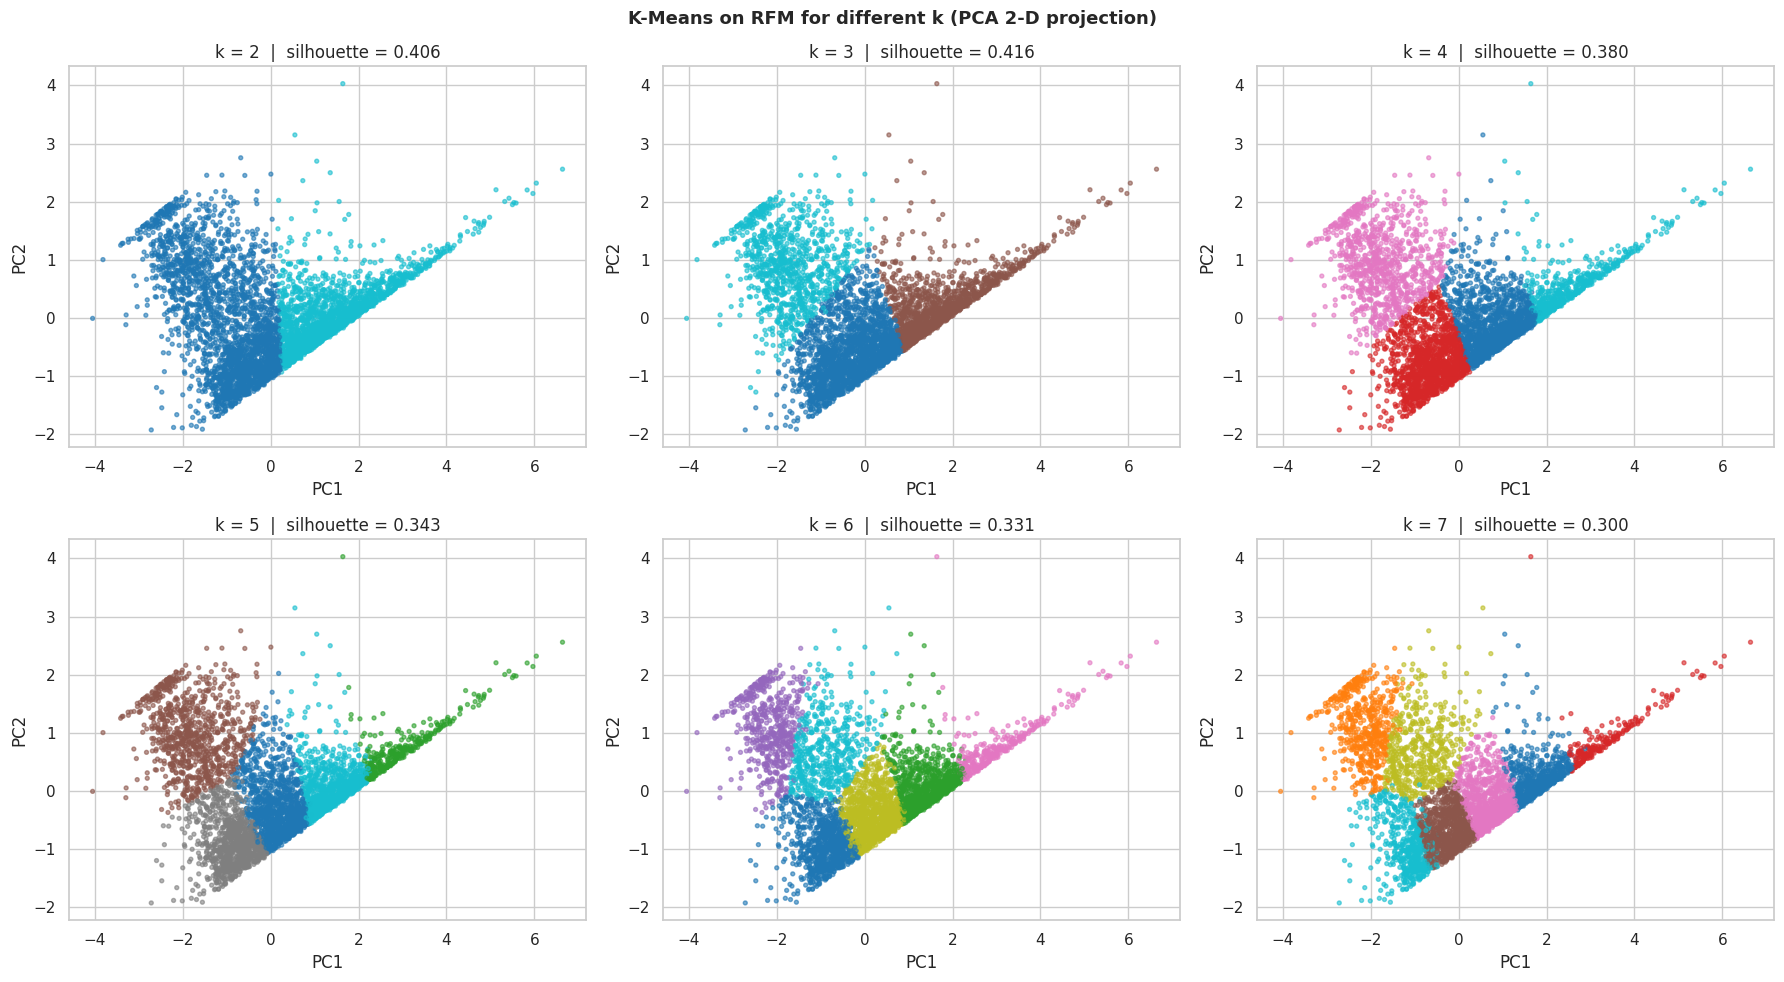

   silhouette  smallest cluster (%)  largest cluster (%)
2       0.406                42.001               57.999
3       0.416                22.568               46.934
4       0.380                12.863               33.356
5       0.343                 7.469               27.778
6       0.331                 7.423               25.611
7       0.300                 4.726               22.361


In [14]:
# Exercise 3.1 — Effect of k (PCA projection, silhouette in the title)
k_values = [2, 3, 4, 5, 6, 7]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
size_rows = {}
for ax, k in zip(axes.flat, k_values):
    km_k = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    labels_k = km_k.fit_predict(X)
    sil_k = silhouette_score(X, labels_k)
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_k, cmap='tab10', s=8, alpha=0.6)
    ax.set_title(f'k = {k}  |  silhouette = {sil_k:.3f}')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    shares = np.bincount(labels_k) / len(labels_k) * 100
    size_rows[k] = {'silhouette': sil_k, 'smallest cluster (%)': shares.min(), 'largest cluster (%)': shares.max()}
plt.suptitle('K-Means on RFM for different k (PCA 2-D projection)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print(pd.DataFrame(size_rows).T.round(3).to_string())

**Observación.**

| k | Silueta | Cluster más pequeño (%) | Cluster más grande (%) |
|:---:|:---:|:---:|:---:|
| 2 | 0.406 | 42.0 | 58.0 |
| **3** | **0.416** | 22.6 | 46.9 |
| 4 | 0.380 | 12.9 | 33.4 |
| 5 | 0.343 | 7.5 | 27.8 |
| 6 | 0.331 | 7.4 | 25.6 |
| 7 | 0.300 | 4.7 | 22.4 |

- La silueta es máxima en **k = 3** (0.416) y desde ahí baja de forma continua.
- Con k = 2 y k = 3 los clusters son grandes bandas contiguas a lo largo de PC1, que funciona como un eje de "valor del cliente": compradores recientes, frecuentes y de alto gasto en un extremo, y clientes perdidos de bajo valor en el otro.
- Con k = 3 los segmentos son claramente interpretables:
  - **Campeones:** 30.5 %; compraron hace unos 30 días, hacen unos 9.8 pedidos y gastan unas £5 494.
  - **Regulares:** 46.9 %; unos 55 días, 2 pedidos y £615.
  - **Perdidos:** 22.6 %; unos 255 días, 1.4 pedidos y £398.
- **Desde k = 4–5** los nuevos clusters se obtienen cortando la misma nube continua en franjas más delgadas, y aparecen segmentos pequeños (7.5 % con k = 5 y 4.7 % con k = 7). Estos segmentos se diferencian solo por pequeños cambios en recencia o gasto, no por un comportamiento distinto, así que es difícil nombrarlos o dirigirles una campaña específica.

**Conclusión:** para un equipo de marketing, k = 3 (como máximo 4) es el último valor que da segmentos claramente distintos y accionables. A partir de k = 5 la segmentación está demasiado fragmentada para tener sentido de negocio.

### Exercise 3.2 — Initialisation Strategies (Intermediate)

Run K-Means 10 times using `n_init=1` with both `init='random'` and
`init='k-means++'`. For each trial record the final inertia and number of
iterations. Plot side-by-side boxplots.

**Key question**: Which initialisation is more stable? Which converges faster?

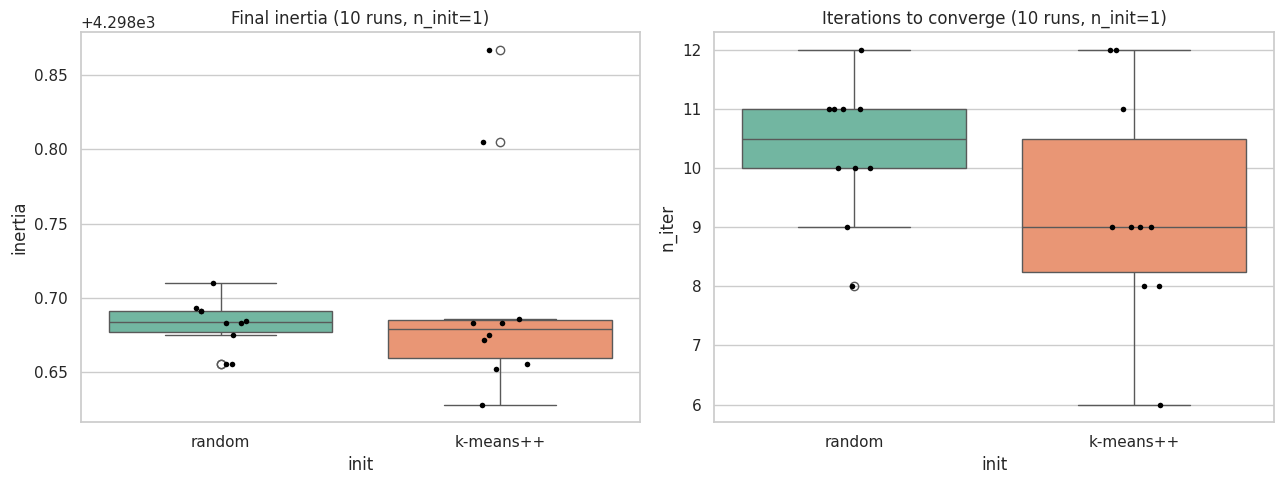

           inertia                         n_iter              
              mean   std      min      max   mean   std min max
init                                                           
k-means++  4298.70  0.07  4298.63  4298.87    9.3  1.89   6  12
random     4298.68  0.02  4298.66  4298.71   10.3  1.16   8  12


In [15]:
# Exercise 3.2 — Initialisation strategies: 10 runs with n_init=1
init_rows = []
for init in ['random', 'k-means++']:
    for trial in range(10):
        km_i = KMeans(n_clusters=K_BEST, init=init, n_init=1, random_state=RANDOM_STATE + trial).fit(X)
        init_rows.append({'init': init, 'trial': trial, 'inertia': km_i.inertia_, 'n_iter': km_i.n_iter_})
df_init = pd.DataFrame(init_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df_init, x='init', y='inertia', ax=axes[0], palette='Set2')
sns.stripplot(data=df_init, x='init', y='inertia', ax=axes[0], color='k', size=4)
axes[0].set_title('Final inertia (10 runs, n_init=1)')
sns.boxplot(data=df_init, x='init', y='n_iter', ax=axes[1], palette='Set2')
sns.stripplot(data=df_init, x='init', y='n_iter', ax=axes[1], color='k', size=4)
axes[1].set_title('Iterations to converge (10 runs, n_init=1)')
plt.tight_layout()
plt.show()

print(df_init.groupby('init')[['inertia', 'n_iter']].agg(['mean', 'std', 'min', 'max']).round(2).to_string())

**Conclusión.**

| Inicialización | Inercia media | Desv. estándar | Rango | Iteraciones (media ± desv.) | Rango de iteraciones |
|---|:---:|:---:|:---:|:---:|:---:|
| `k-means++` | 4298.70 | 0.07 | 4298.63 – 4298.87 | 9.3 ± 1.89 | 6 – 12 |
| `random` | 4298.68 | 0.02 | 4298.66 – 4298.71 | 10.3 ± 1.16 | 8 – 12 |

- **Estabilidad:** en este dataset, **ambas inicializaciones son prácticamente igual de estables**. Las 10 corridas de cada una terminan en la misma solución: la diferencia máxima de inercia es de 0.24 sobre 4 298, menos del 0.01 %. `random` incluso tiene una dispersión ligeramente menor (0.02 vs 0.07). Ninguna corrida quedó atrapada en un óptimo local claramente peor.
- **Velocidad:** **`k-means++` converge algo más rápido**, con una iteración menos en promedio (9.3 vs 10.3) y un mínimo de 6 iteraciones frente a 8. Su siembra coloca los centroides iniciales separados entre sí y cerca de la solución final. A cambio, el número de iteraciones varía más entre corridas.
- **Por qué no se nota la ventaja teórica:** con k = 3 y datos RFM que forman una nube continua con una única partición dominante, casi cualquier inicialización termina en el mismo óptimo. La ventaja de `k-means++` en estabilidad, es decir, evitar que dos centroides empiecen en la misma región densa, aparece sobre todo con muchos clusters o con estructuras más complejas.
- Por eso scikit-learn usa `k-means++` por defecto. Con `init='random'` conviene usar un `n_init` mayor como protección, aunque aquí no fue necesario.

## Section 4: Hierarchical Clustering <a id='4'></a>

**Agglomerative** hierarchical clustering starts with each point as its own cluster
and merges the two closest clusters at each step. The merge history is visualised
as a **dendrogram**.

The *linkage criterion* defines "distance between clusters":

| Linkage | Definition | Tendency |
|---|---|---|
| Single | min pairwise distance | chaining, elongated clusters |
| Complete | max pairwise distance | compact, similar-size clusters |
| Average | mean pairwise distance | compromise |
| **Ward** | minimise within-cluster variance | spherical, balanced (default choice) |

**Complexity**: O(n² log n) — we subsample to 400 customers for the dendrogram.

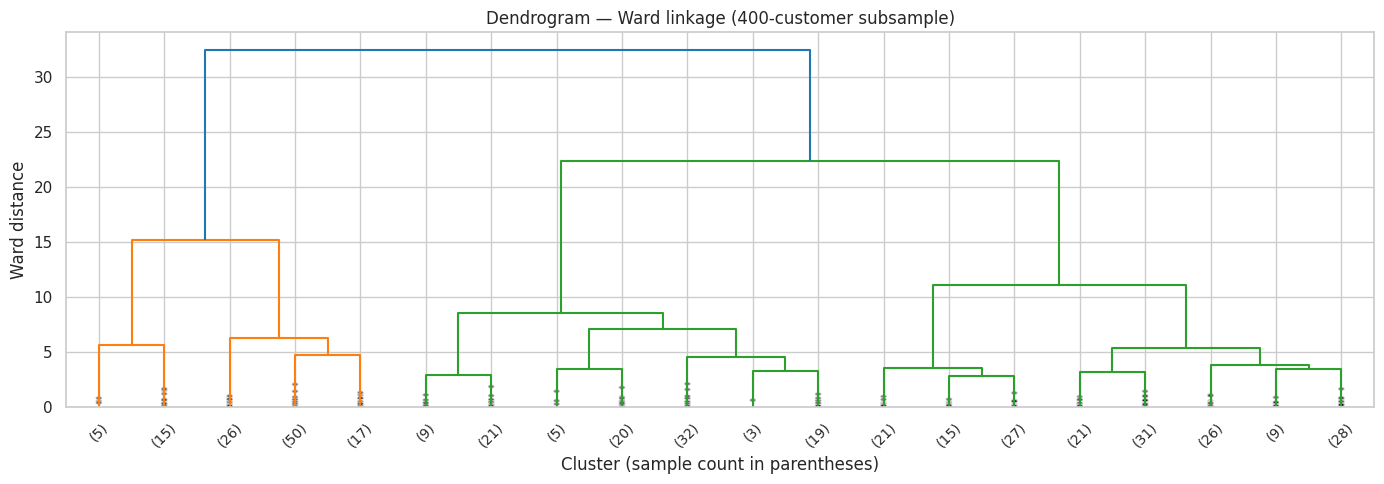

In [16]:
# Dendrogram on a subsample for readability
np.random.seed(RANDOM_STATE)
sub_idx = np.random.choice(len(X), size=min(400, len(X)), replace=False)
X_sub = X[sub_idx]

Z = linkage(X_sub, method='ward')

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(Z, ax=ax, truncate_mode='lastp', p=20,
           leaf_rotation=45, leaf_font_size=10, show_contracted=True)
ax.set_title(f'Dendrogram — Ward linkage (400-customer subsample)')
ax.set_xlabel('Cluster (sample count in parentheses)')
ax.set_ylabel('Ward distance')
plt.tight_layout()
plt.show()

In [17]:
# Fit on full dataset and compare to K-Means
agg = AgglomerativeClustering(n_clusters=K_BEST, linkage='ward')
rfm['Cluster_Agg'] = agg.fit_predict(X)

sil_km  = silhouette_score(X, rfm['Cluster_KM'])
sil_agg = silhouette_score(X, rfm['Cluster_Agg'])
print(f"Silhouette — K-Means: {sil_km:.4f}  |  Hierarchical (Ward): {sil_agg:.4f}")
print(f"\nCluster sizes (Hierarchical):")
print(rfm['Cluster_Agg'].value_counts().sort_index().to_string())

Silhouette — K-Means: 0.4156  |  Hierarchical (Ward): 0.3959

Cluster sizes (Hierarchical):
Cluster_Agg
0    1528
1    1937
2     873


### Exercise 4.1 — Linkage Comparison (Intermediate)

Plot dendrograms for Ward, Complete, Average, and Single linkage in a 2 × 2
grid (same 400-customer subsample). Below each dendrogram, cut the tree at
`k = K_BEST` and print the resulting cluster sizes.

**Key question**: Which linkage produces the most balanced clusters?
Why does Single linkage behave differently?

    ward: cluster sizes at k=3 -> [178, 113, 109]
complete: cluster sizes at k=3 -> [233, 133, 34]
 average: cluster sizes at k=3 -> [288, 92, 20]
  single: cluster sizes at k=3 -> [398, 1, 1]


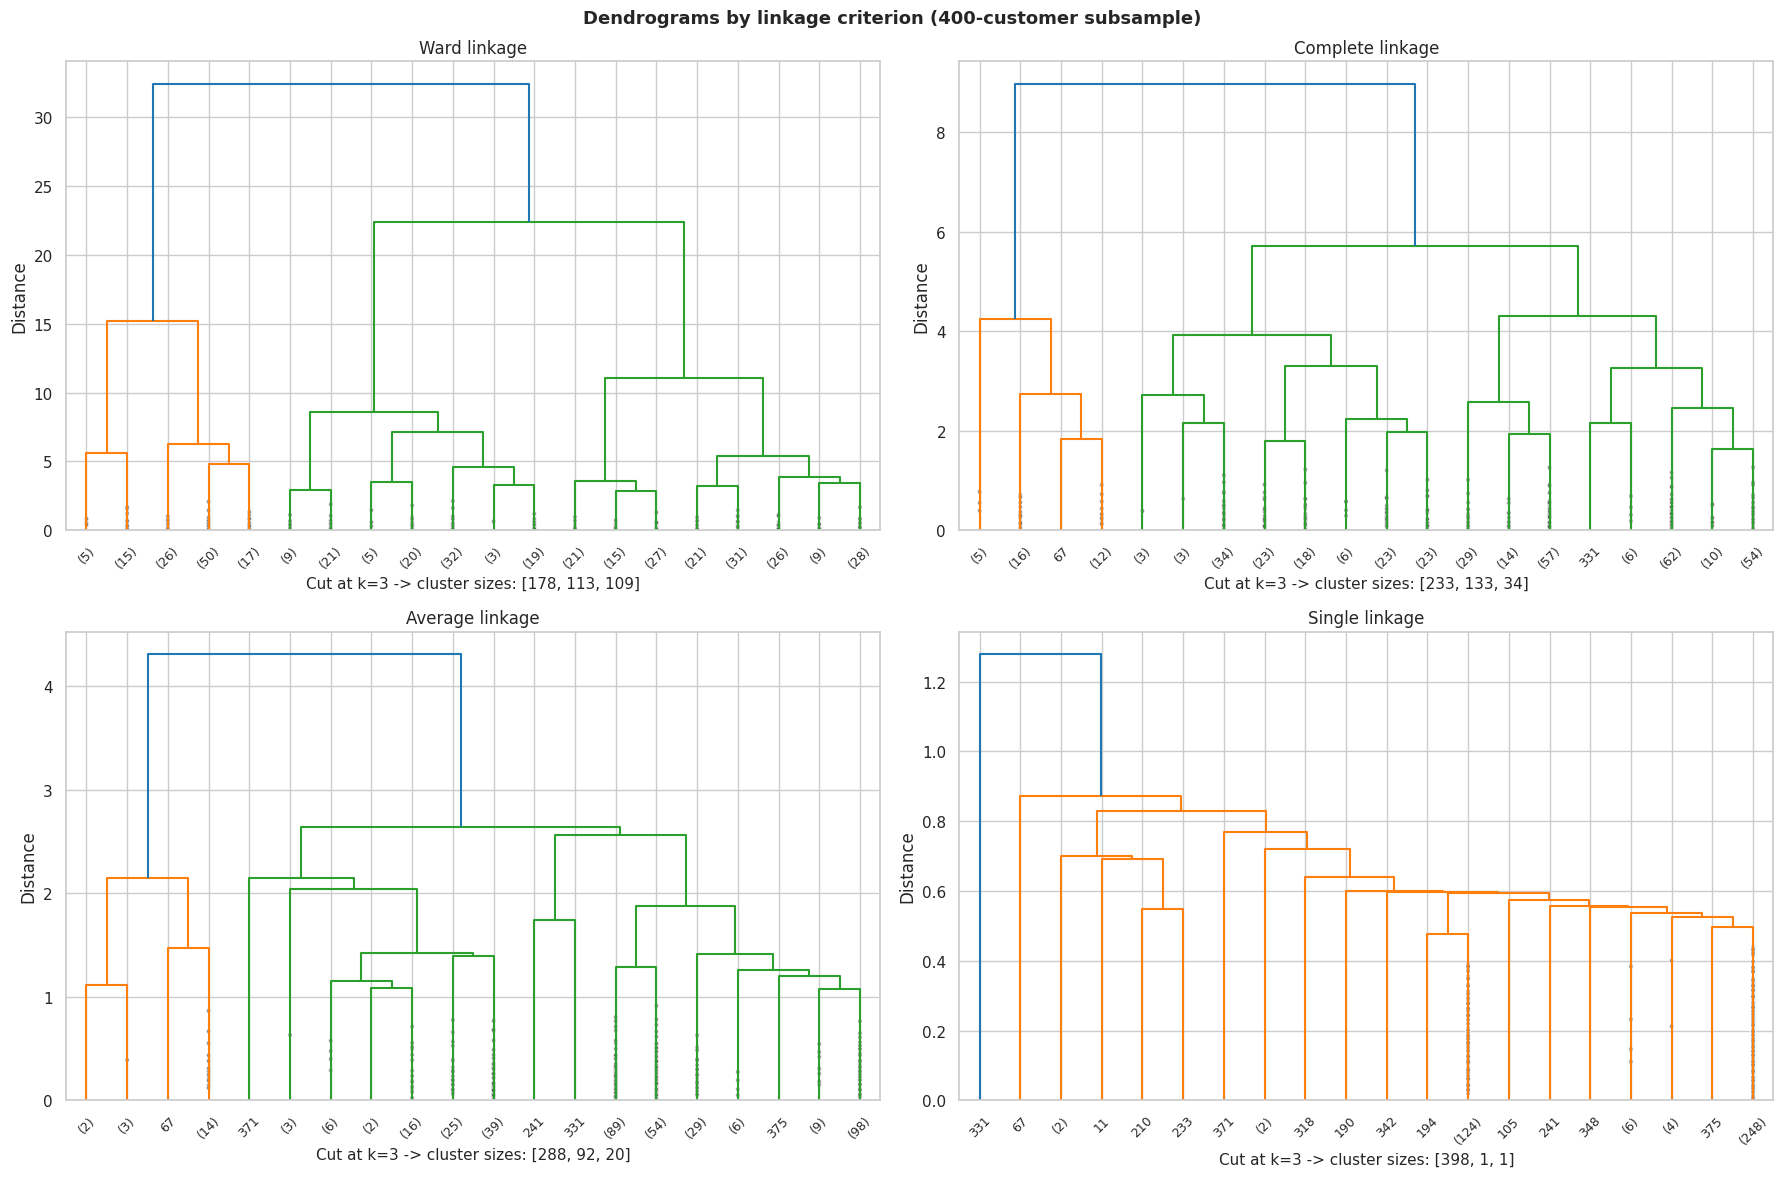

In [18]:
# Exercise 4.1 — Linkage comparison on the same 400-customer subsample
linkages = ['ward', 'complete', 'average', 'single']
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
link_sizes = {}
for ax, method in zip(axes.flat, linkages):
    Z_m = linkage(X_sub, method=method)
    dendrogram(Z_m, ax=ax, truncate_mode='lastp', p=20, leaf_rotation=45, leaf_font_size=9, show_contracted=True)
    labels_m = fcluster(Z_m, K_BEST, criterion='maxclust')
    sizes = np.bincount(labels_m)[1:]
    link_sizes[method] = sorted(sizes.tolist(), reverse=True)
    ax.set_title(f'{method.capitalize()} linkage')
    ax.set_ylabel('Distance')
    ax.set_xlabel(f'Cut at k={K_BEST} -> cluster sizes: {sorted(sizes.tolist(), reverse=True)}', fontsize=11)
    print(f"{method:>8s}: cluster sizes at k={K_BEST} -> {sorted(sizes.tolist(), reverse=True)}")
plt.suptitle('Dendrograms by linkage criterion (400-customer subsample)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Observación.** Tamaños de los clusters al cortar el árbol en k = 3 (submuestra de 400 clientes):

| Linkage | Tamaños de los clusters |
|---|:---:|
| **Ward** | [178, 113, 109] |
| Complete | [233, 133, 34] |
| Average | [288, 92, 20] |
| Single | [398, 1, 1] |

- **Ward produce los clusters más balanceados.** Cada fusión minimiza el aumento de la varianza intra-cluster, lo que genera grupos compactos de tamaño comparable.
- **Complete** es el siguiente en balance, aunque ya genera un cluster pequeño (34 clientes).
- **Average** y sobre todo **single** dan cortes muy desbalanceados: un cluster gigante con casi todos los clientes y uno o dos clusters diminutos formados por unos pocos valores atípicos, como los clientes de gasto extremo.
- **Single linkage se comporta distinto por el efecto de encadenamiento (*chaining*).** La distancia entre dos clusters es la distancia entre su par de puntos *más cercano*. En una nube continua como la de RFM, sin huecos entre grupos, los clusters crecen absorbiendo uno a uno al punto vecino más próximo. El dendrograma muestra muchas fusiones a alturas muy pequeñas y similares, y los únicos saltos grandes corresponden a puntos aislados. Por eso, al cortar en k = 3, single linkage solo separa 2 atípicos individuales del resto (398 / 1 / 1).

## Section 5: Gaussian Mixture Models <a id='5'></a>

A **Gaussian Mixture Model** assumes the data is generated by a mixture of k
Gaussian distributions. The **EM algorithm** iterates between:

- **E-step**: compute the *posterior probability* that each point belongs to each
  component (soft assignment)
- **M-step**: update means, covariances, and mixing weights to maximise likelihood

The *covariance type* controls model flexibility:

| Type | Parameters | Flexibility |
|---|---|---|
| `spherical` | one variance per component | lowest |
| `diag` | diagonal covariance per component | medium |
| `tied` | one full covariance shared by all | medium |
| `full` | full covariance per component | highest |

**Model selection**: BIC and AIC penalise model complexity (lower is better).

In [19]:
gmm = GaussianMixture(n_components=K_BEST, covariance_type='full',
                      random_state=RANDOM_STATE, n_init=5)
gmm.fit(X)
rfm['Cluster_GMM'] = gmm.predict(X)
proba = gmm.predict_proba(X)
rfm['Max_Posterior'] = proba.max(axis=1)

print(f"Converged: {gmm.converged_}  |  BIC: {gmm.bic(X):.1f}  |  AIC: {gmm.aic(X):.1f}")
print(f"\nCluster sizes (GMM):")
print(rfm['Cluster_GMM'].value_counts().sort_index().to_string())

Converged: True  |  BIC: 25437.6  |  AIC: 25252.7

Cluster sizes (GMM):
Cluster_GMM
0    1113
1    1455
2    1770


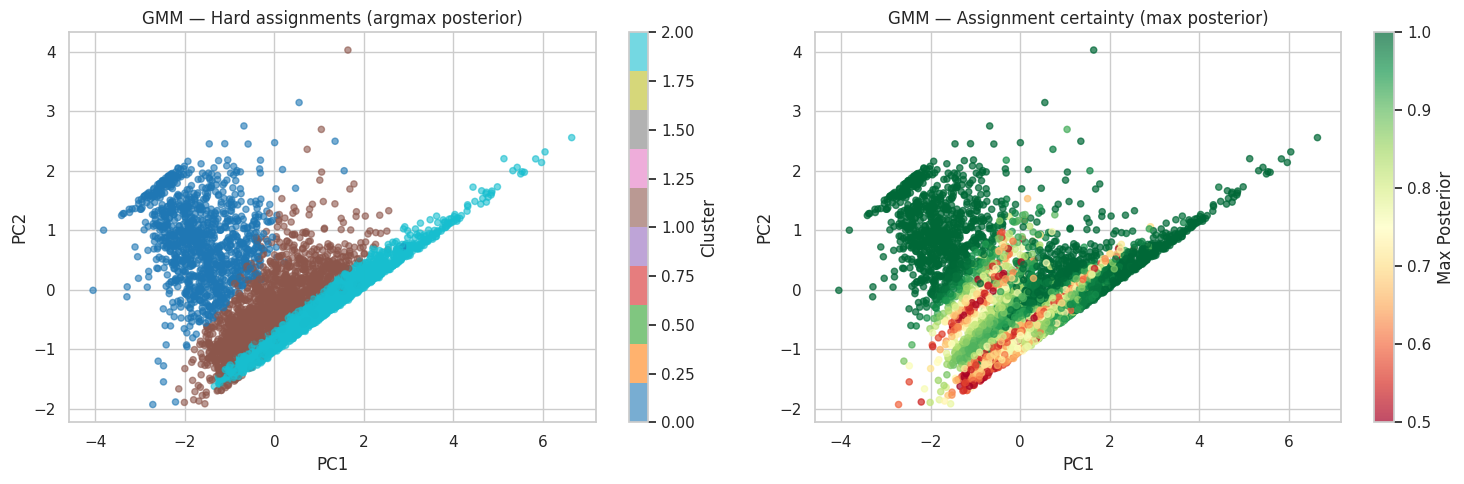

In [20]:
# Visualise assignments vs uncertainty
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sc1 = axes[0].scatter(X_pca[:, 0], X_pca[:, 1],
                       c=rfm['Cluster_GMM'], cmap='tab10', alpha=0.6, s=20)
axes[0].set_title('GMM — Hard assignments (argmax posterior)')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')
plt.colorbar(sc1, ax=axes[0], label='Cluster')

sc2 = axes[1].scatter(X_pca[:, 0], X_pca[:, 1],
                       c=rfm['Max_Posterior'], cmap='RdYlGn',
                       alpha=0.7, s=20, vmin=0.5, vmax=1.0)
axes[1].set_title('GMM — Assignment certainty (max posterior)')
axes[1].set_xlabel('PC1'); axes[1].set_ylabel('PC2')
plt.colorbar(sc2, ax=axes[1], label='Max Posterior')

plt.tight_layout()
plt.show()

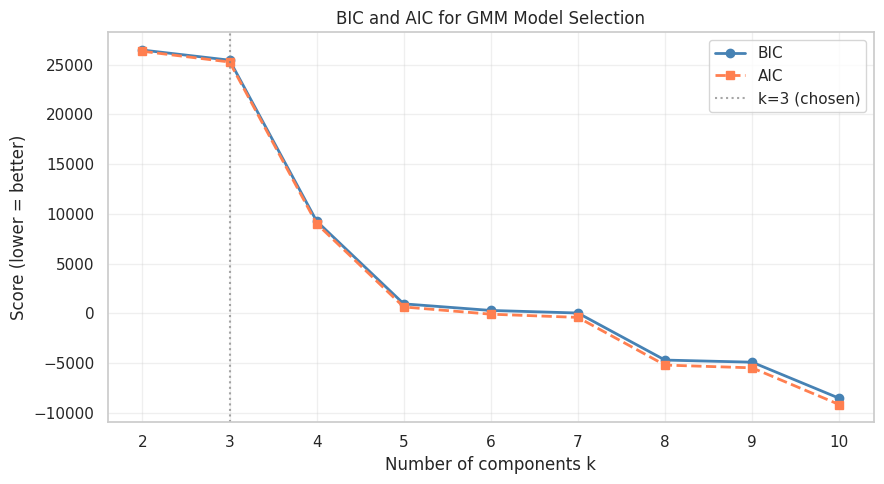

In [21]:
# BIC / AIC curves for model selection
k_range_gmm = range(2, 11)
bic_scores, aic_scores = [], []

for k in k_range_gmm:
    g = GaussianMixture(n_components=k, covariance_type='full',
                        random_state=RANDOM_STATE, n_init=3)
    g.fit(X)
    bic_scores.append(g.bic(X))
    aic_scores.append(g.aic(X))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(k_range_gmm, bic_scores, 'o-', label='BIC', color='steelblue', linewidth=2)
ax.plot(k_range_gmm, aic_scores, 's--', label='AIC', color='coral', linewidth=2)
ax.axvline(x=K_BEST, color='gray', linestyle=':', alpha=0.7, label=f'k={K_BEST} (chosen)')
ax.set_xlabel('Number of components k')
ax.set_ylabel('Score (lower = better)')
ax.set_title('BIC and AIC for GMM Model Selection')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Reading the BIC / AIC curves

Both BIC and AIC reward goodness-of-fit (higher likelihood) but **penalise model
complexity** — every extra component adds parameters (a mean, a covariance, a
mixing weight), so the penalty grows with k. BIC penalises more harshly than AIC,
which is why the two curves separate slightly at large k. For both, **lower is
better**, and the textbook recipe is to pick the k at the *minimum*, or where the
curve stops dropping meaningfully.

**What this figure actually shows is a cautionary case:**

- BIC and AIC sit almost on top of each other and **keep decreasing all the way to
  k = 10** (down to roughly −8 000 / −9 000). There is **no true minimum** in the
  range — read literally, "lowest score wins" would select k = 10.
- The decline is **steepest from k = 2 → 4**, then **flattens dramatically after
  k ≈ 5**. Each component beyond that buys very little extra likelihood.

This is a classic GMM pitfall: with flexible (full) covariance, the model can
always raise its likelihood a little by adding a component to chase fine structure
— often **overfitting** noise rather than discovering real segments. The complexity
penalty here is not strong enough to overcome that, so the curve never bottoms out.

### Why k = 3 is still a good choice

- **It sits at the elbow.** The dramatic drop happens by k ≈ 4 and the curve is
  essentially flat afterward. k = 3 captures the bulk of the achievable likelihood
  gain before diminishing returns set in — the same elbow logic used for K-Means
  inertia. Adding components past this point yields tiny, hard-to-interpret splits.
- **It agrees with every other diagnostic.** The K-Means silhouette peaks at k = 3,
  the Ward dendrogram's largest gaps support 2–3 clusters, and the full grid search
  in Section 6 ranks k = 3 first for all methods. BIC/AIC alone are ambiguous here,
  but **consensus across independent methods** is strong evidence.
- **It is interpretable and actionable.** k = 3 maps cleanly onto the
  Champions / Regular / Lapsed RFM segments — a story a marketing team can act on.
  The k = 10 solution that minimises BIC would produce tiny fragments with no
  business meaning.

**The lesson:** BIC and AIC are *guides, not oracles*. When the curve declines
monotonically, do not blindly take the global minimum — combine it with the elbow
location, agreement across methods, and interpretability. Here all three point to
**k = 3**, even though the raw BIC/AIC numbers do not single it out.

### Exercise 5.1 — Covariance Type Comparison (Intermediate)

Plot BIC vs k for all four covariance types (`full`, `tied`, `diag`,
`spherical`) on the same axes. Then print, for each type, the k that minimises
BIC.

**Key question**: Does `full` always win? What is the trade-off with
`spherical` or `diag`?

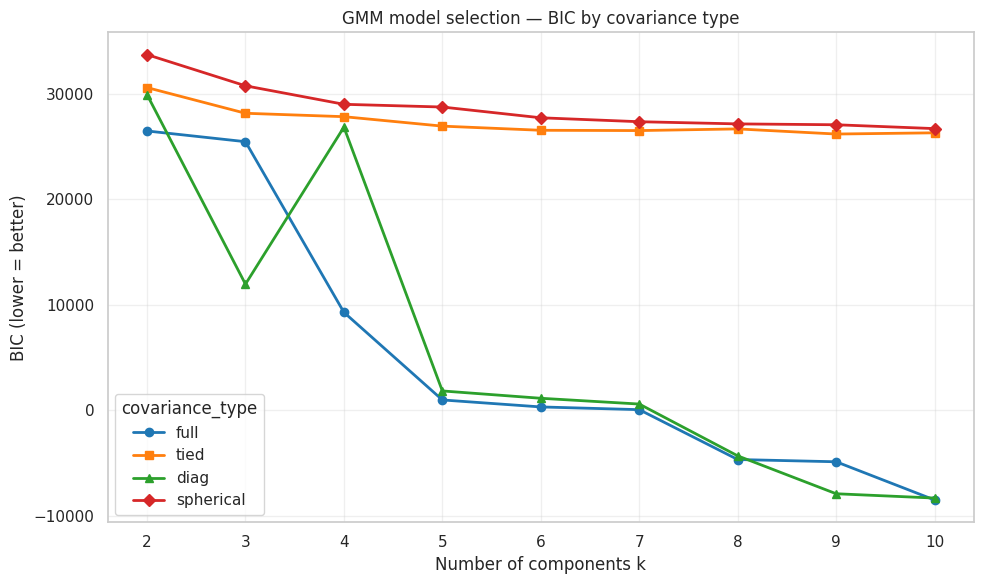

     full: k minimising BIC = 10  (BIC = -8511.2)
     tied: k minimising BIC =  9  (BIC = 26163.4)
     diag: k minimising BIC = 10  (BIC = -8329.2)
spherical: k minimising BIC = 10  (BIC = 26677.8)

Overall best: covariance_type = 'full', k = 10


In [22]:
# Exercise 5.1 — BIC vs k for every covariance type
cov_types = ['full', 'tied', 'diag', 'spherical']
k_range_cov = range(2, 11)
bic_by_type = {}
for ct in cov_types:
    bic_by_type[ct] = [GaussianMixture(n_components=k, covariance_type=ct, random_state=RANDOM_STATE, n_init=3)
                       .fit(X).bic(X) for k in k_range_cov]

fig, ax = plt.subplots(figsize=(10, 6))
for ct, marker in zip(cov_types, ['o', 's', '^', 'D']):
    ax.plot(list(k_range_cov), bic_by_type[ct], marker=marker, linewidth=2, label=ct)
ax.set_xlabel('Number of components k'); ax.set_ylabel('BIC (lower = better)')
ax.set_title('GMM model selection — BIC by covariance type')
ax.legend(title='covariance_type'); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

bic_df = pd.DataFrame(bic_by_type, index=list(k_range_cov))
for ct in cov_types:
    print(f"{ct:>9s}: k minimising BIC = {bic_df[ct].idxmin():2d}  (BIC = {bic_df[ct].min():.1f})")
print(f"\nOverall best: covariance_type = '{bic_df.min().idxmin()}', k = {bic_df[bic_df.min().idxmin()].idxmin()}")

**¿Gana siempre `full`?** No en todos los k. Mínimo de BIC por tipo de covarianza (k entre 2 y 10):

| `covariance_type` | k que minimiza el BIC | BIC mínimo |
|---|:---:|:---:|
| `full` | 10 | **−8 511.2** |
| `diag` | 10 | −8 329.2 |
| `tied` | 9 | 26 163.4 |
| `spherical` | 10 | 26 677.8 |

- **`full` obtiene el menor BIC global**, pero `diag` queda prácticamente empatado, y en la gráfica **`diag` es mejor que `full` en k = 3** (≈ 12 000 vs ≈ 25 400) **y en k = 9** (≈ −7 900 vs ≈ −4 900). Así que `full` no gana en todos los valores de k.
- **Ningún tipo muestra un mínimo claro dentro del rango.** Las cuatro curvas tienden a seguir bajando hasta k = 9–10, así que el BIC por sí solo no selecciona un número razonable de segmentos. Esto es coherente con la discusión de la sección 5, donde k = 3 se justifica con el codo, el consenso entre métodos y la interpretabilidad.
- **`tied` y `spherical`** dan curvas suaves con BIC alto (≈ 26 000–34 000). Imponen una misma forma a todos los componentes (`tied`) o componentes redondos (`spherical`), y no pueden describir bien variables correlacionadas, como Frequency y Monetary: los clientes que compran más seguido también gastan más.
- **`full` y `diag`** tienen un comportamiento muy distinto: BIC que cae a valores **negativos** (≈ −8 500) y **saltos erráticos**. Por ejemplo, `diag` cae a ≈ 12 000 en k = 3, sube a ≈ 27 000 en k = 4 y vuelve a caer en k = 5. Una explicación probable es que algunos componentes "colapsan" sobre valores repetidos de los datos: al menos el 25 % de los clientes tiene exactamente 1 pedido, así que comparten el mismo valor escalado de Frequency. Un componente con varianza casi nula en esa dimensión hace que la densidad, y con ella la verosimilitud, se dispare. Esto no refleja un mejor ajuste real, sino una solución degenerada que solo frena el parámetro `reg_covar`. `tied` y `spherical` no pueden hacer esto, porque no permiten varianzas por componente y por dimensión.

**Compromiso (*trade-off*):**

- `spherical` y `diag` son más baratos y más estables cuando hay pocas muestras o muchas dimensiones. Sin embargo, imponen una forma que no corresponde a variables correlacionadas, y `diag` también puede degenerar.
- `full` es el más flexible y modela clusters elípticos y rotados, a costa de más parámetros (6 de covarianza por componente en 3D, frente a 3 de `diag` y 1 de `spherical`), más riesgo de sobreajuste y de soluciones degeneradas, y un ajuste más lento en alta dimensión.

### Exercise 5.2 — Uncertain Customers (Advanced)

Identify customers whose max posterior probability is below 0.60 — these are
customers that GMM could not confidently assign to any cluster.

1. Print the count and percentage of uncertain customers.
2. Compare their mean RFM values to the rest.
3. Plot uncertain customers in red over the PCA scatter of all customers.

**What do uncertain customers have in common?**

Uncertain customers: 297 of 4338 (6.8%)

RFM comparison (mean and median):
                   Recency        Frequency        Monetary       
                      mean median      mean median     mean median
Max_Posterior                                                     
Confident (>=0.60)    95.9   54.0       4.4    2.0   2141.6  697.6
Uncertain (<0.60)     47.1   33.0       2.0    2.0    866.6  428.9

GMM cluster of the uncertain customers:
Cluster_GMM
0     32
1    133
2    132

Most common pair of competing components:
(1, 2)    232
(0, 1)     65


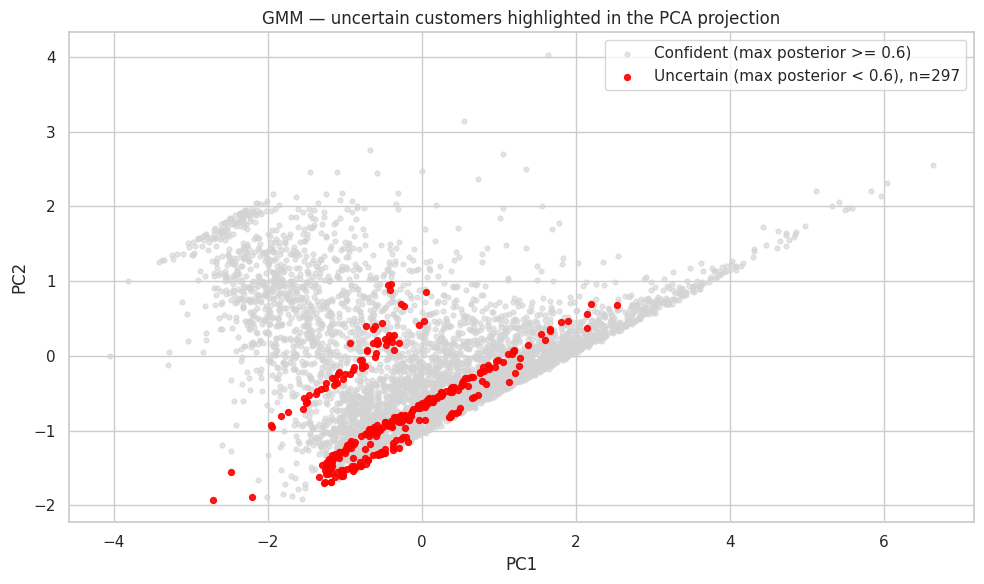

In [23]:
# Exercise 5.2 — Uncertain customers (max posterior < 0.60)
THRESH = 0.60
uncertain = rfm['Max_Posterior'] < THRESH
n_unc = int(uncertain.sum())
print(f"Uncertain customers: {n_unc} of {len(rfm)} ({n_unc / len(rfm):.1%})")

comp = rfm.groupby(uncertain.map({True: 'Uncertain (<0.60)', False: 'Confident (>=0.60)'}))[
    ['Recency', 'Frequency', 'Monetary']].agg(['mean', 'median']).round(1)
print("\nRFM comparison (mean and median):")
print(comp.to_string())
print("\nGMM cluster of the uncertain customers:")
print(rfm.loc[uncertain, 'Cluster_GMM'].value_counts().sort_index().to_string())
# Which pair of components are they torn between?
top2 = np.argsort(-proba, axis=1)[:, :2]
pairs = pd.Series([tuple(sorted(p)) for p in top2[uncertain.values]]).value_counts()
print("\nMost common pair of competing components:")
print(pairs.head().to_string())

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X_pca[~uncertain.values, 0], X_pca[~uncertain.values, 1], c='lightgrey', s=12, alpha=0.6,
           label=f'Confident (max posterior >= {THRESH})')
ax.scatter(X_pca[uncertain.values, 0], X_pca[uncertain.values, 1], c='red', s=18, alpha=0.9,
           label=f'Uncertain (max posterior < {THRESH}), n={n_unc}')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.set_title('GMM — uncertain customers highlighted in the PCA projection')
ax.legend(); plt.tight_layout(); plt.show()

**¿Qué tienen en común los clientes inciertos?** Hay **297 clientes (6.8 %)** con una probabilidad posterior máxima menor que 0.60.

| Grupo | Recency (media / mediana) | Frequency (media / mediana) | Monetary (media / mediana) |
|---|:---:|:---:|:---:|
| Seguros (≥ 0.60) | 95.9 / 54.0 días | 4.4 / 2.0 | £2 142 / £698 |
| **Inciertos (< 0.60)** | **47.1 / 33.0 días** | **2.0 / 2.0** | **£867 / £429** |

- **Son clientes recientes pero poco desarrollados.** Compraron más recientemente que el resto (mediana de 33 días frente a 54), pero tienen menos pedidos (media de 2.0 frente a 4.4) y gastan bastante menos (mediana de £429 frente a £698). Encajan con el perfil de **clientes nuevos o en formación**: compraron hace poco, pero todavía no han mostrado si serán compradores frecuentes de alto valor u ocasionales.
- **Están en la frontera entre dos componentes específicos.** El 78 % (232 de 297) duda entre los componentes 1 y 2, y el resto (65) entre los componentes 0 y 1. En la proyección PCA aparecen en las zonas de transición entre componentes, no en el centro de los clusters.
- **Interpretación de negocio:** son clientes "en transición", el objetivo natural de campañas de desarrollo o fidelización, como incentivar una segunda o tercera compra.
- Esta información solo está disponible porque el GMM hace asignaciones suaves (probabilísticas). K-Means los habría asignado sin más a un cluster, ocultando su ambigüedad.

## Section 6: Comparative Analysis on Online Retail <a id='6'></a>

With all three methods fitted, we can now compare them side by side using
**internal** evaluation metrics — metrics that do not require ground-truth labels.

| Metric | Direction | Measures |
|---|---|---|
| Silhouette score | ↑ higher is better | separation vs cohesion |
| Davies-Bouldin index | ↓ lower is better | avg ratio of intra-to-inter cluster distance |
| Calinski-Harabasz index | ↑ higher is better | ratio of between-to-within cluster dispersion |

In [24]:
methods_rfm = {
    'K-Means':             rfm['Cluster_KM'],
    'Hierarchical (Ward)': rfm['Cluster_Agg'],
    'GMM':                 rfm['Cluster_GMM'],
}

rows = []
for name, labels in methods_rfm.items():
    rows.append({
        'Method': name,
        'Silhouette ↑':        silhouette_score(X, labels),
        'Davies-Bouldin ↓':    davies_bouldin_score(X, labels),
        'Calinski-Harabasz ↑': calinski_harabasz_score(X, labels),
    })

df_comparison = pd.DataFrame(rows).set_index('Method').round(4)
df_comparison

,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑
Method,,,
K-Means,0.4156,0.8247,4394.5458
Hierarchical (Ward),0.3959,0.8455,4031.9434
GMM,0.1906,1.5748,1891.3734


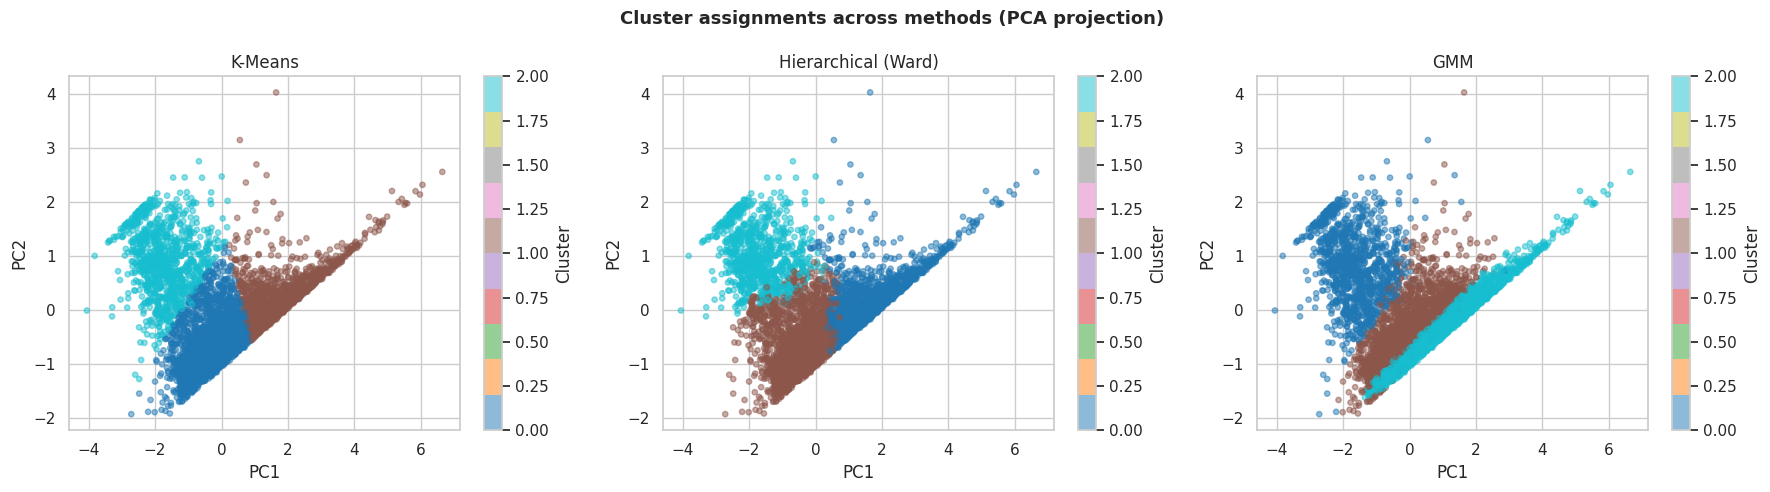

In [25]:
# Side-by-side PCA scatter plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titles    = ['K-Means', 'Hierarchical (Ward)', 'GMM']
col_names = ['Cluster_KM', 'Cluster_Agg', 'Cluster_GMM']

for ax, title, col in zip(axes, titles, col_names):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1],
                    c=rfm[col], cmap='tab10', alpha=0.5, s=15)
    ax.set_title(title)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    plt.colorbar(sc, ax=ax, label='Cluster')

plt.suptitle('Cluster assignments across methods (PCA projection)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Why these metrics are unfair to GMM

The table ranks GMM well below K-Means and Hierarchical on all three metrics
(Silhouette 0.19 vs 0.42, Davies-Bouldin 1.57 vs 0.82, Calinski-Harabasz 1891 vs
4395). It is tempting to conclude GMM is the worst method here — but that
conclusion is wrong. The problem is a **mismatch between what these metrics reward
and what GMM optimises**, not a failure of GMM.

**All three internal metrics have a built-in bias toward compact, spherical, hard
clusters:**

- They are computed from **Euclidean distances to centroids**. Silhouette compares
  each point's distance to its own cluster vs the nearest other cluster;
  Davies-Bouldin and Calinski-Harabasz both rely on within- vs between-cluster
  *distance/dispersion* ratios. All implicitly assume clusters are round blobs of
  similar size.
- **K-Means optimises exactly this geometry.** Its objective *is* within-cluster
  squared distance, so it is almost guaranteed to score best on metrics built from
  the same quantity — it is being judged on its home turf. Ward linkage minimises
  the same variance criterion, so it lands a close second.
- **GMM does not optimise geometry at all.** It maximises *likelihood* under a
  probabilistic model, and it is free to fit **elongated, rotated, overlapping
  clusters of unequal size** (full covariance). Points in the overlap region get a
  low silhouette even when the model has assigned them correctly with a sensible
  posterior. The metric penalises overlap; GMM is designed to *model* overlap.

In short: **a low Silhouette/DB/CH for GMM measures how non-spherical and
overlapping its clusters are, not how wrong they are.** Judging GMM with these
metrics is like grading a probabilistic model with a ruler.

### How to evaluate GMM fairly

Match the evaluation to the model's objective:

| Tool | What it measures | Why it suits GMM |
|---|---|---|
| **BIC / AIC** | likelihood penalised for complexity | scores GMM on its own objective (see Section 5) |
| **Log-likelihood** | fit of the generative model | native quantity GMM maximises |
| **Posterior confidence** | per-point assignment certainty | exploits soft assignment (see Exercise 5.2) |
| **External metrics (ARI/NMI)** | agreement with ground truth | bias-free when labels exist (see Section 7) |

### The advantages of GMM these metrics cannot see

- **Soft (probabilistic) assignment.** Every customer gets a probability vector
  over clusters, not a single hard label. This surfaces *borderline* customers
  (Exercise 5.2 found ~6.8% with max posterior < 0.6) — information K-Means
  discards by forcing every point to 100% membership.
- **Flexible cluster shapes.** With full covariance, clusters can be elliptical,
  correlated, and differently sized/oriented — a far better fit when segments are
  not round, which is the norm for real RFM data.
- **A generative, probabilistic model.** Because GMM defines a density, you can
  evaluate the likelihood of new points, sample synthetic customers, detect
  outliers (low likelihood), and select k with principled criteria (BIC/AIC)
  instead of heuristics.
- **Handles overlapping segments.** Real customer segments blend into one another;
  GMM models that blend explicitly rather than drawing artificial hard boundaries
  through dense regions.

**Bottom line:** on this dataset K-Means produces the most geometrically compact
*hard* partition, which is exactly what Silhouette/DB/CH reward — so it "wins" the
table. But if the goal is **uncertainty-aware segmentation, non-spherical clusters,
or a generative model of customer behaviour**, GMM is the stronger tool, and it
should be judged by BIC/AIC and posterior confidence rather than by centroid-based
internal metrics.

### Exercise 6.1 — Full Grid Search (Advanced)

For each k ∈ {3, 4, 5, 6} and each method (K-Means, Hierarchical, GMM), compute
Silhouette, Davies-Bouldin, and Calinski-Harabász. Present results as a tidy
DataFrame sorted by Silhouette descending.

**Based on your table**: Which (method, k) combination would you recommend to
a marketing team and why?

In [26]:
# Exercise 6.1 — Full grid search: (method, k) x internal metrics
grid_rows = []
for k in [3, 4, 5, 6]:
    candidates = {
        'K-Means':             KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE).fit_predict(X),
        'Hierarchical (Ward)': AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X),
        'GMM (full)':          GaussianMixture(n_components=k, covariance_type='full', n_init=3,
                                               random_state=RANDOM_STATE).fit(X).predict(X),
    }
    for method, lab in candidates.items():
        shares = np.bincount(lab) / len(lab)
        grid_rows.append({'Method': method, 'k': k,
                          'Silhouette ↑': silhouette_score(X, lab),
                          'Davies-Bouldin ↓': davies_bouldin_score(X, lab),
                          'Calinski-Harabasz ↑': calinski_harabasz_score(X, lab),
                          'Smallest cluster %': 100 * shares.min()})

df_grid = (pd.DataFrame(grid_rows)
           .sort_values('Silhouette ↑', ascending=False)
           .reset_index(drop=True)
           .round(4))
display(df_grid)
best = df_grid.iloc[0]
print(f"Best by silhouette: {best['Method']} with k={best['k']}")
print("Rank by each metric (1 = best):")
ranks = pd.DataFrame({'Method': df_grid['Method'], 'k': df_grid['k'],
                      'rank Sil': df_grid['Silhouette ↑'].rank(ascending=False),
                      'rank DB': df_grid['Davies-Bouldin ↓'].rank(ascending=True),
                      'rank CH': df_grid['Calinski-Harabasz ↑'].rank(ascending=False)})
ranks['mean rank'] = ranks[['rank Sil', 'rank DB', 'rank CH']].mean(axis=1)
print(ranks.sort_values('mean rank').head(5).to_string(index=False))

,Method,k,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,Smallest cluster %
0,K-Means,3,0.4156,0.8247,4394.5458,22.5680
1,Hierarchical (Ward),3,0.3959,0.8455,4031.9434,20.1245
2,K-Means,4,0.3805,0.8570,4354.4077,12.8631
3,Hierarchical (Ward),4,0.3741,0.8055,3623.1259,3.7114
4,K-Means,5,0.3433,0.9409,4022.8159,7.4689
5,K-Means,6,0.3307,0.9763,3837.1409,7.4228
6,Hierarchical (Ward),5,0.2990,0.9815,3413.6928,3.7114
7,Hierarchical (Ward),6,0.2761,1.0669,3213.5295,3.7114
8,GMM (full),3,0.1907,1.5759,1890.0080,25.6339
9,GMM (full),6,0.1513,1.7028,1729.8189,9.4283


Best by silhouette: K-Means with k=3
Rank by each metric (1 = best):
             Method  k  rank Sil  rank DB  rank CH  mean rank
            K-Means  3       1.0      2.0      1.0   1.333333
Hierarchical (Ward)  3       2.0      3.0      3.0   2.666667
            K-Means  4       3.0      4.0      2.0   3.000000
Hierarchical (Ward)  4       4.0      1.0      6.0   3.666667
            K-Means  5       5.0      5.0      4.0   4.666667


**Recomendación.** Las 5 mejores combinaciones según el ranking promedio de las tres métricas:

| Método | k | Silueta ↑ | Davies-Bouldin ↓ | Calinski-Harabasz ↑ | Cluster más pequeño | Ranking promedio |
|---|:---:|:---:|:---:|:---:|:---:|:---:|
| **K-Means** | **3** | **0.4156** | 0.8247 | **4394.5** | 22.6 % | **1.33** |
| Ward | 3 | 0.3959 | 0.8455 | 4031.9 | 20.1 % | 2.67 |
| K-Means | 4 | 0.3805 | 0.8570 | 4354.4 | 12.9 % | 3.00 |
| Ward | 4 | 0.3741 | **0.8055** | 3623.1 | 3.7 % | 3.67 |
| K-Means | 5 | 0.3433 | 0.9409 | 4022.8 | 7.5 % | 4.67 |

- **K-Means con k = 3** es el mejor en silueta y en Calinski-Harabasz, y el segundo en Davies-Bouldin. El mejor Davies-Bouldin lo tiene **Ward con k = 4** (0.8055), pero a costa de un cluster de apenas el 3.7 % de los clientes y del peor Calinski-Harabasz del grupo.
- Para K-Means y Ward, la silueta y el Calinski-Harabasz empeoran a medida que crece k. **Para GMM no hay un patrón monótono**: su silueta en k = 6 (0.151) es mayor que en k = 4 (0.085) y k = 5 (0.079). En todos los casos GMM queda por debajo, por las razones ya discutidas: estas métricas favorecen clusters esféricos y asignaciones duras.

**Para el equipo de marketing recomiendo K-Means con k = 3** por tres razones:

1. Tiene el mejor desempeño combinado en las métricas internas (ranking promedio de 1.33).
2. Sus tres segmentos corresponden directamente a perfiles RFM interpretables (Campeones / Regulares / Perdidos) sin clusters diminutos poco accionables (el más pequeño tiene el 22.6 %).
3. K-Means tiene método `predict`, así que los clientes nuevos se pueden asignar a un segmento sin reentrenar, algo que Ward no permite.

Si el equipo necesita un cuarto segmento, por ejemplo para separar a los clientes nuevos de los regulares, la siguiente opción es **K-Means con k = 4**, aceptando una silueta menor (0.381). El GMM con k = 3 sigue siendo útil como complemento para identificar a los clientes inciertos o en transición (ejercicio 5.2).

## Section 7: Dataset 2 — HAR & External Evaluation (ARI / NMI) <a id='7'></a>

Internal metrics measure cluster *geometry*, but they cannot tell you whether the
clusters align with meaningful real-world categories.  When ground-truth labels
exist, use **external metrics**:

| Metric | Range | Meaning |
|---|---|---|
| **ARI** (Adjusted Rand Index) | −1 … 1 | 0 = random, 1 = perfect match, adjusted for chance |
| **NMI** (Normalised Mutual Info) | 0 … 1 | information shared between cluster and true labels |

### Human Activity Recognition (HAR)

Collected from 30 volunteers wearing a Samsung Galaxy S II on the waist.
Accelerometer and gyroscope measurements at 50 Hz → 561 engineered features.
**6 activity labels**: WALKING, WALKING_UPSTAIRS, WALKING_DOWNSTAIRS,
SITTING, STANDING, LAYING.

In [27]:
print("Loading HAR from OpenML (cached after first download)…")
har = fetch_openml('har', version=1, as_frame=False, parser='auto')
X_har_raw = har.data.astype(float)

# OpenML 'har' encodes activities as numeric codes '1'..'6'.
# Map them to the standard UCI HAR activity names.
HAR_ACTIVITY = {
    '1': 'WALKING', '2': 'WALKING_UPSTAIRS', '3': 'WALKING_DOWNSTAIRS',
    '4': 'SITTING', '5': 'STANDING', '6': 'LAYING',
}
y_har_str = np.array([HAR_ACTIVITY[c] for c in har.target])

# Map string labels → integers
activity_names = sorted(np.unique(y_har_str))
label_map = {name: i for i, name in enumerate(activity_names)}
y_har = np.array([label_map[l] for l in y_har_str])

print(f"Shape: {X_har_raw.shape}")
print(f"Activities: {activity_names}")
pd.Series(y_har_str).value_counts()

Loading HAR from OpenML (cached after first download)…
Shape: (10299, 561)
Activities: [np.str_('LAYING'), np.str_('SITTING'), np.str_('STANDING'), np.str_('WALKING'), np.str_('WALKING_DOWNSTAIRS'), np.str_('WALKING_UPSTAIRS')]


,count
LAYING,1944
STANDING,1906
SITTING,1777
WALKING,1722
WALKING_UPSTAIRS,1544
WALKING_DOWNSTAIRS,1406


In [28]:
# Scale -> PCA (retain 95% of the variance)
print("Scaling and reducing with PCA…")
scaler_har = StandardScaler()
X_har_scaled = scaler_har.fit_transform(X_har_raw)

pca_har = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_har_pca = pca_har.fit_transform(X_har_scaled)
print(f"Retained {pca_har.n_components_} PCs "
      f"out of {X_har_scaled.shape[1]} features "
      f"({pca_har.explained_variance_ratio_.sum():.1%} variance)")

Scaling and reducing with PCA…
Retained 104 PCs out of 561 features (95.0% variance)


In [29]:
print("Running t-SNE (PCA dim → 2 dims) — may take ~2 minutes…")
tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE,
            n_jobs=-1, n_iter=1000)
X_har_tsne = tsne.fit_transform(X_har_pca)
print("Done.")

Running t-SNE (PCA dim → 2 dims) — may take ~2 minutes…
Done.


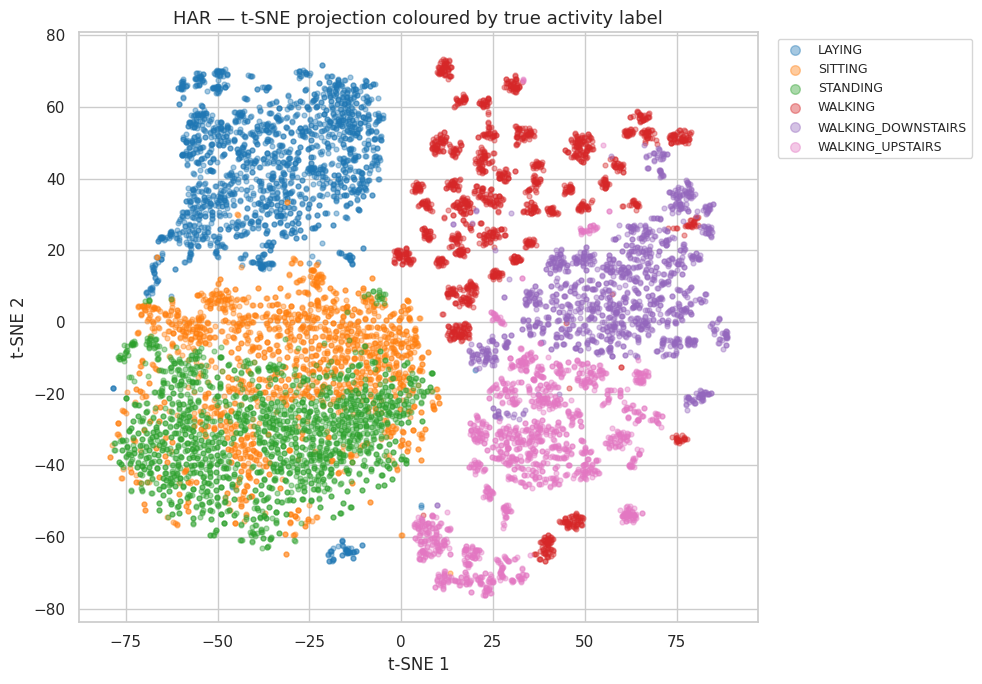

In [30]:
# t-SNE coloured by true activity
colors = plt.cm.tab10(np.linspace(0, 0.6, len(activity_names)))

fig, ax = plt.subplots(figsize=(10, 7))
for i, (name, color) in enumerate(zip(activity_names, colors)):
    mask = y_har == i
    ax.scatter(X_har_tsne[mask, 0], X_har_tsne[mask, 1],
               c=[color], alpha=0.4, s=12, label=name)

ax.set_title('HAR — t-SNE projection coloured by true activity label', fontsize=13)
ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9, markerscale=2)
plt.tight_layout()
plt.show()

In [31]:
# Fit all three clustering methods (k = number of activities = 6)
N_ACT = len(activity_names)

km_har  = KMeans(n_clusters=N_ACT, init='k-means++', n_init=10, random_state=RANDOM_STATE)
agg_har = AgglomerativeClustering(n_clusters=N_ACT, linkage='ward')
gmm_har = GaussianMixture(n_components=N_ACT, covariance_type='full',
                           random_state=RANDOM_STATE, n_init=3)

pred_km  = km_har.fit_predict(X_har_pca)
pred_agg = agg_har.fit_predict(X_har_pca)
pred_gmm = gmm_har.fit_predict(X_har_pca)

har_rows = []
for name, pred in [('K-Means', pred_km),
                    ('Hierarchical (Ward)', pred_agg),
                    ('GMM', pred_gmm)]:
    har_rows.append({
        'Method':              name,
        'ARI ↑':               adjusted_rand_score(y_har, pred),
        'NMI ↑':               normalized_mutual_info_score(y_har, pred),
        'Silhouette ↑':        silhouette_score(X_har_pca, pred),
        'Davies-Bouldin ↓':    davies_bouldin_score(X_har_pca, pred),
    })

pd.DataFrame(har_rows).set_index('Method').round(4)

,ARI ↑,NMI ↑,Silhouette ↑,Davies-Bouldin ↓
Method,,,,
K-Means,0.4193,0.5593,0.1223,2.2385
Hierarchical (Ward),0.5004,0.6240,0.1167,2.2476
GMM,0.3448,0.5241,0.1067,2.4030


**Discussion**: Do the internal metrics (Silhouette, Davies-Bouldin) agree with
the external metrics (ARI, NMI) about which method is best?  This is the central
lesson of this section: internal metrics measure geometry, external metrics measure
*semantic alignment*.

**Respuesta.** No, las métricas internas y externas **no coinciden** en cuál es el mejor método en HAR (k = 6):

| Método | ARI ↑ | NMI ↑ | Silueta ↑ | Davies-Bouldin ↓ |
|---|:---:|:---:|:---:|:---:|
| K-Means | 0.4193 | 0.5593 | **0.1223** | **2.2385** |
| Hierarchical (Ward) | **0.5004** | **0.6240** | 0.1167 | 2.2476 |
| GMM | 0.3448 | 0.5241 | 0.1067 | 2.4030 |

- **Las métricas internas eligen K-Means**, con la mayor silueta y el menor Davies-Bouldin. Es lógico, porque K-Means optimiza justamente la compacidad respecto a los centroides, que es lo que esas métricas premian.
- **Las métricas externas eligen Ward** por un margen claro: ARI de 0.500 frente a 0.419 (+0.08) y NMI de 0.624 frente a 0.559. Es decir, la partición de Ward se alinea mejor con las actividades reales.
- Además, las diferencias en las métricas internas son mínimas (silueta de 0.122 frente a 0.117) y todas son muy bajas (< 0.13). Esto indica que en este espacio de 104 componentes principales no hay clusters geométricamente bien separados, aunque sí existe estructura semántica que ARI y NMI detectan.
- GMM queda último en todas las métricas.

**Lección:** las métricas internas miden la *geometría* de los clusters y las externas miden la *alineación semántica* con las categorías reales. Si solo hubiéramos usado silueta o Davies-Bouldin, habríamos elegido K-Means, que no es el método que mejor recupera las actividades.

### Exercise 7.1 — ARI / NMI vs k (Intermediate)

Using K-Means on the PCA-reduced HAR features, sweep k from 2 to 10.
For each k, compute ARI, NMI, and Silhouette.  Plot all three as a function of k
on a 1 × 3 subplot grid.

**Key question**: Does the Silhouette score peak at k = 6 (the true number of
activities)?  Does ARI?  Why might they disagree?

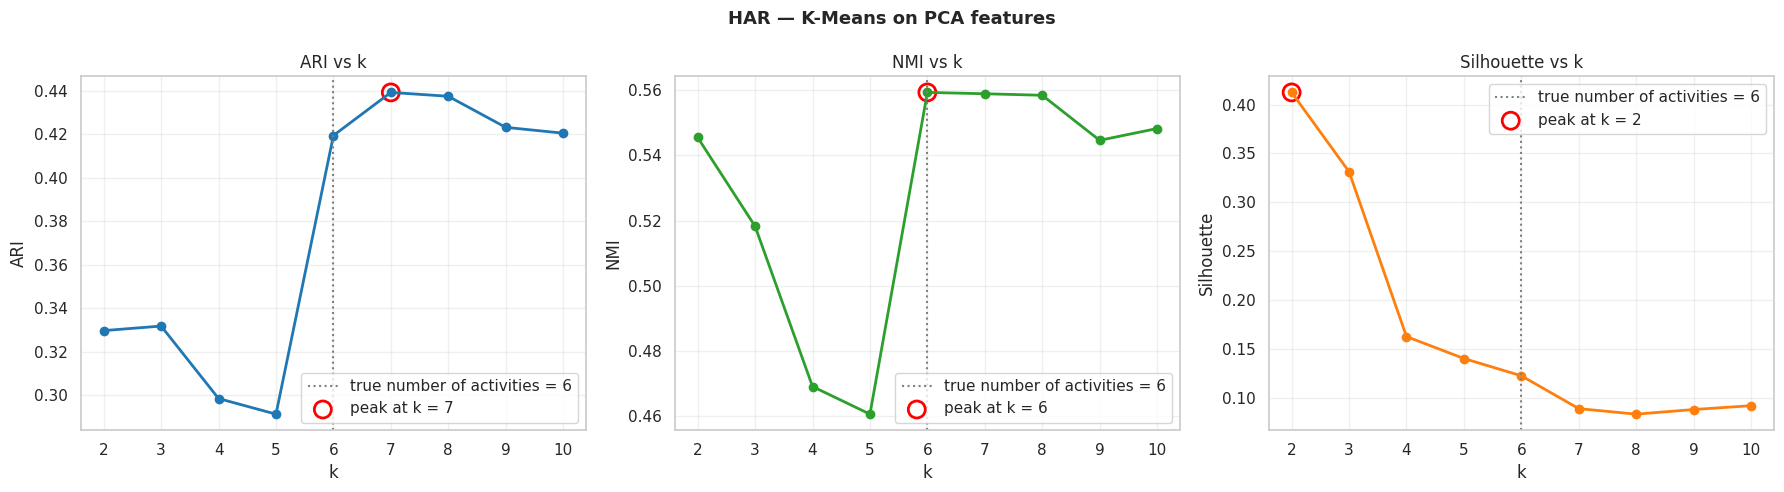

       ARI     NMI  Silhouette
k                             
2   0.3296  0.5455      0.4125
3   0.3317  0.5183      0.3313
4   0.2984  0.4692      0.1625
5   0.2912  0.4607      0.1400
6   0.4193  0.5593      0.1223
7   0.4391  0.5589      0.0886
8   0.4373  0.5584      0.0830
9   0.4231  0.5446      0.0877
10  0.4204  0.5482      0.0917
       ARI peaks at k = 7
       NMI peaks at k = 6
Silhouette peaks at k = 2


In [32]:
# Exercise 7.1 — ARI / NMI / Silhouette vs k on HAR (K-Means on PCA features)
k_range_har = list(range(2, 11))
har_k_rows = []
for k in k_range_har:
    lab = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE).fit_predict(X_har_pca)
    har_k_rows.append({'k': k,
                       'ARI': adjusted_rand_score(y_har, lab),
                       'NMI': normalized_mutual_info_score(y_har, lab),
                       'Silhouette': silhouette_score(X_har_pca, lab)})
df_har_k = pd.DataFrame(har_k_rows).set_index('k')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric, color in zip(axes, ['ARI', 'NMI', 'Silhouette'], ['tab:blue', 'tab:green', 'tab:orange']):
    ax.plot(df_har_k.index, df_har_k[metric], 'o-', color=color, linewidth=2)
    ax.axvline(N_ACT, color='gray', ls=':', label=f'true number of activities = {N_ACT}')
    best_k_m = df_har_k[metric].idxmax()
    ax.scatter([best_k_m], [df_har_k[metric].max()], s=150, facecolors='none', edgecolors='red', linewidths=2,
               label=f'peak at k = {best_k_m}')
    ax.set_xlabel('k'); ax.set_ylabel(metric); ax.set_title(f'{metric} vs k'); ax.legend(); ax.grid(alpha=0.3)
plt.suptitle('HAR — K-Means on PCA features', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print(df_har_k.round(4).to_string())
for metric in ['ARI', 'NMI', 'Silhouette']:
    print(f"{metric:>10s} peaks at k = {df_har_k[metric].idxmax()}")

**¿La silueta alcanza su máximo en k = 6? ¿Y el ARI?**

| k | ARI | NMI | Silueta |
|:---:|:---:|:---:|:---:|
| 2 | 0.3296 | 0.5455 | **0.4125** |
| 3 | 0.3317 | 0.5183 | 0.3313 |
| 4 | 0.2984 | 0.4692 | 0.1625 |
| 5 | 0.2912 | 0.4607 | 0.1400 |
| 6 | 0.4193 | **0.5593** | 0.1223 |
| 7 | **0.4391** | 0.5589 | 0.0886 |
| 8 | 0.4373 | 0.5584 | 0.0830 |
| 9 | 0.4231 | 0.5446 | 0.0877 |
| 10 | 0.4204 | 0.5482 | 0.0917 |

- **La silueta NO tiene su máximo en k = 6, sino en k = 2** (0.4125), y desde ahí cae con fuerza hasta ≈ 0.09. La estructura geométrica más fuerte del espacio de variables de HAR es la división entre actividades **dinámicas** (caminar, subir y bajar escaleras) y **estáticas** (sentado, de pie, acostado), que están muy separadas en el espacio de los sensores. Lo respalda el NMI en k = 2 (0.5455), casi tan alto como en k = 6: esa sola división ya captura buena parte de la información de las etiquetas. Dividir más solo corta esos dos grandes bloques en subclusters que se tocan, así que la silueta empeora.
- **El ARI tampoco tiene su máximo exactamente en k = 6, sino en k = 7** (0.4391), aunque k = 6 a 8 quedan muy cerca (0.419–0.439). **El NMI sí alcanza su máximo en k = 6** (0.5593), prácticamente empatado con k = 7 (0.5589). Las métricas externas favorecen valores de k cercanos al número real de actividades, porque premian la coincidencia con las 6 etiquetas.
- El ARI **cae en k = 4–5** (≈ 0.29), por debajo de k = 2–3. Las particiones intermedias cortan los bloques de forma que no coincide con ninguna actividad. En k = 6 el ARI salta a 0.42, cuando los clusters empiezan a corresponder con actividades individuales.

**¿Por qué no coinciden?** La silueta es una métrica *interna*: solo mide geometría, es decir, clusters compactos, convexos y bien separados. ARI y NMI son métricas *externas*: miden el acuerdo con categorías definidas por personas. Las actividades no son igual de separables: varios pares, como sentado vs de pie o las variantes de caminar, se solapan mucho en el espacio de variables. Por eso los clusters "naturales" desde el punto de vista geométrico no coinciden uno a uno con las etiquetas. Sin etiquetas, la silueta nos habría llevado a elegir k = 2 en lugar de las 6 actividades reales.

### Exercise 7.2 — Static Activities Only (Advanced)

The six HAR activities split naturally into *dynamic* (WALKING, WALKING_UPSTAIRS,
WALKING_DOWNSTAIRS) and *static* (SITTING, STANDING, LAYING).

1. Filter the dataset to the three static activities only.
2. Fit K-Means with k = 3.
3. Compute ARI and NMI; compare to the full-dataset result.

**Hypothesis**: Static activities should be harder to distinguish (similar
body postures, low-frequency signals).  Does the data support this?

                        n samples     ARI     NMI
All 6 activities (k=6)    10299.0  0.4193  0.5593
Static only (k=3)          5627.0  0.3599  0.3862
Dynamic only (k=3)         4672.0  0.1173  0.1230

Contingency table — static activities vs K-Means clusters:
Cluster           0     1    2
True activity                 
LAYING         1558    53  333
SITTING          91  1247  439
STANDING          0  1356  550


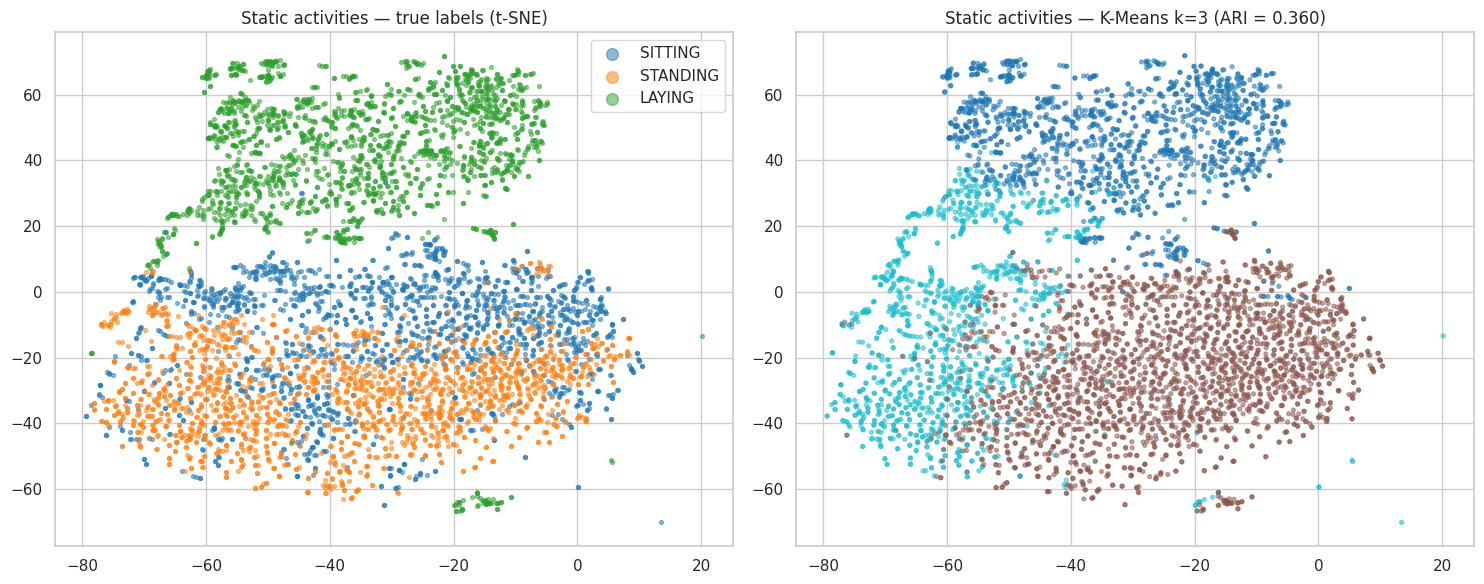

In [33]:
# Exercise 7.2 — Static activities only (SITTING, STANDING, LAYING)
static_acts = ['SITTING', 'STANDING', 'LAYING']
dynamic_acts = ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS']
mask_static = np.isin(y_har_str, static_acts)
mask_dynamic = np.isin(y_har_str, dynamic_acts)

def kmeans_subset(mask, k=3):
    lab = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE).fit_predict(X_har_pca[mask])
    return lab, adjusted_rand_score(y_har[mask], lab), normalized_mutual_info_score(y_har[mask], lab)

lab_static, ari_static, nmi_static = kmeans_subset(mask_static)
lab_dynamic, ari_dynamic, nmi_dynamic = kmeans_subset(mask_dynamic)
ari_full = adjusted_rand_score(y_har, pred_km)          # K-Means k=6 on all activities (Section 7)
nmi_full = normalized_mutual_info_score(y_har, pred_km)

cmp_static = pd.DataFrame({
    'All 6 activities (k=6)':     {'n samples': len(y_har), 'ARI': ari_full, 'NMI': nmi_full},
    'Static only (k=3)':          {'n samples': int(mask_static.sum()), 'ARI': ari_static, 'NMI': nmi_static},
    'Dynamic only (k=3)':         {'n samples': int(mask_dynamic.sum()), 'ARI': ari_dynamic, 'NMI': nmi_dynamic},
}).T
print(cmp_static.round(4).to_string())

print("\nContingency table — static activities vs K-Means clusters:")
print(pd.crosstab(pd.Series(y_har_str[mask_static], name='True activity'),
                  pd.Series(lab_static, name='Cluster')).to_string())

# Visual check on the t-SNE embedding computed in Section 7
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name in static_acts:
    m = y_har_str[mask_static] == name
    axes[0].scatter(X_har_tsne[mask_static][m, 0], X_har_tsne[mask_static][m, 1], s=8, alpha=0.5, label=name)
axes[0].set_title('Static activities — true labels (t-SNE)'); axes[0].legend(markerscale=3)
axes[1].scatter(X_har_tsne[mask_static][:, 0], X_har_tsne[mask_static][:, 1], c=lab_static, cmap='tab10', s=8, alpha=0.5)
axes[1].set_title(f'Static activities — K-Means k=3 (ARI = {ari_static:.3f})')
plt.tight_layout(); plt.show()

**¿Se confirma la hipótesis?**

| Subconjunto | n | ARI | NMI |
|---|:---:|:---:|:---:|
| Las 6 actividades (k = 6) | 10 299 | 0.4193 | 0.5593 |
| **Solo estáticas (k = 3)** | 5 627 | **0.3599** | **0.3862** |
| Solo dinámicas (k = 3) | 4 672 | 0.1173 | 0.1230 |

Tabla de contingencia de las actividades estáticas frente a los clusters de K-Means:

| Actividad real | Cluster 0 | Cluster 1 | Cluster 2 |
|---|:---:|:---:|:---:|
| LAYING | **1 558 (80 %)** | 53 (3 %) | 333 (17 %) |
| SITTING | 91 (5 %) | **1 247 (70 %)** | 439 (25 %) |
| STANDING | 0 (0 %) | **1 356 (71 %)** | 550 (29 %) |

- **Frente al conjunto completo, la hipótesis se confirma en parte.** Separar solo las actividades estáticas es más difícil que el problema completo: ARI de 0.360 frente a 0.419 y NMI de 0.386 frente a 0.559. La tabla muestra dónde está el problema:
  - **LAYING** queda bien separado en su mayoría (80 % en el cluster 0), porque al estar acostado la gravedad actúa sobre otro eje del teléfono. Aun así, el 17 % cae en el cluster 2.
  - **SITTING y STANDING no se distinguen**: el cluster 1 mezcla al 70 % de sentados con el 71 % de parados, y el cluster 2 es una mezcla de las tres actividades. Ambas son posturas erguidas e inmóviles que producen señales de acelerómetro y giroscopio casi idénticas.
- **Frente a las actividades dinámicas, la hipótesis NO se confirma.** El subconjunto dinámico es mucho **más difícil** de separar (ARI 0.117, NMI 0.123) que el estático. Caminar, subir escaleras y bajar escaleras producen patrones periódicos muy parecidos, y K-Means casi no logra distinguirlos.
- **Cuidado al comparar:** el ARI del conjunto completo se beneficia de la división "fácil" entre dinámicas y estáticas, que aporta mucho acuerdo con las etiquetas. Dentro de cada grupo esa ayuda desaparece, por eso ambos subconjuntos dan valores menores.

**Conclusión:** la dificultad no está en las actividades estáticas como grupo, sino en pares específicos de actividades parecidas: sentado vs de pie entre las estáticas y, sobre todo, las tres variantes de caminar entre las dinámicas.

## Section 8: Real-World Considerations <a id='8'></a>

### Preprocessing is decisive

Feature scaling is non-negotiable for distance-based methods (K-Means,
Hierarchical).  Skewed distributions (like Monetary) should be log-transformed
before scaling.  PCA before clustering reduces noise and speeds up computation —
particularly important for high-dimensional data like HAR.

### Choosing an algorithm

| Algorithm | Strengths | Weaknesses |
|---|---|---|
| K-Means | Fast, scalable, easy to interpret | Assumes spherical clusters, sensitive to init |
| Hierarchical | No k required up front, produces dendrogram, deterministic | O(n²) memory/time, no predict() for new data |
| GMM | Soft assignments, flexible covariance shapes | Slower, can collapse/overfit, needs good init |

### Internal vs external validation

Use **internal** metrics (Silhouette, Davies-Bouldin) when you have no labels —
which is the typical case.  If you can label even a small validation set, compute
**external** metrics (ARI, NMI) on it — they are strictly more informative.

### Scalability

For very large datasets:
- Replace `KMeans` with `MiniBatchKMeans` (sklearn, same API)
- Hierarchical clustering is impractical above ~50 k samples; use BIRCH or HDBSCAN
- GMM with `diag` covariance scales better than `full`

### Communicating results

Cluster labels are arbitrary integers.  Always *profile* each cluster (mean RFM
values, mode activity) and give it a human-readable name before presenting to
stakeholders.

## Section 9: Final Challenges (optional) <a id='9'></a>

### Challenge 9.1 — Image Colour Quantization

K-Means can compress an image by replacing each pixel colour with its nearest
cluster centroid — effectively reducing the palette to k colours.

Apply K-Means to the pixels of sklearn's built-in `china.jpg` sample image with
k ∈ {2, 4, 8, 16}. Display the original and all four quantized versions.

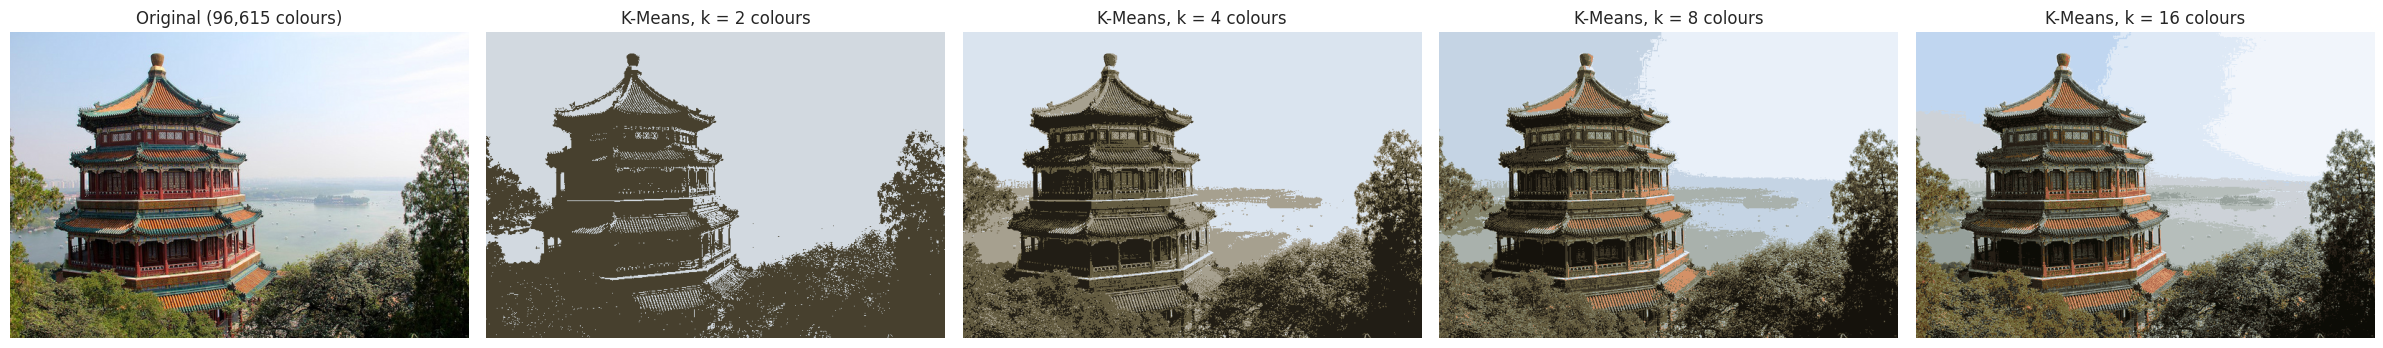

In [34]:
# Challenge 9.1 — Image colour quantization with K-Means
china = load_sample_image('china.jpg')
img = np.array(china, dtype=np.float64) / 255.0           # (h, w, 3) in [0, 1]
h, w, c = img.shape
pixels = img.reshape(-1, c)

# Fit on a random subsample of pixels (fast), then assign every pixel to its nearest centroid
pixel_sample = shuffle(pixels, random_state=RANDOM_STATE, n_samples=10_000)
quantized = {}
for k in [2, 4, 8, 16]:
    km_img = KMeans(n_clusters=k, n_init=4, random_state=RANDOM_STATE).fit(pixel_sample)
    quantized[k] = km_img.cluster_centers_[km_img.predict(pixels)].reshape(h, w, c)

fig, axes = plt.subplots(1, 5, figsize=(24, 5))
axes[0].imshow(img); axes[0].set_title(f'Original ({len(np.unique(pixels, axis=0)):,} colours)')
for ax, k in zip(axes[1:], [2, 4, 8, 16]):
    ax.imshow(quantized[k]); ax.set_title(f'K-Means, k = {k} colours')
for ax in axes:
    ax.axis('off')
plt.tight_layout(); plt.show()

**Observación.**

- Con **k = 2** solo sobrevive la estructura de claro/oscuro.
- Con **k = 4–8** las regiones principales (cielo, edificio, vegetación) ya son reconocibles.
- Con **k = 16** la imagen es visualmente muy parecida a la original, aunque usa solo 16 colores en lugar de decenas de miles.

En términos de compresión, cada píxel puede guardarse como un índice de 4 bits a una paleta de 16 colores, en lugar de 24 bits (8 por canal RGB). Eso reduce unas 6 veces la información de color. Es un ejemplo de K-Means como cuantización vectorial: cada píxel se reemplaza por el centroide (color) más cercano.

### Challenge 9.2 — Beat the Benchmark (HAR)

The best ARI you achieved in Section 7 is your benchmark.

Try to improve it by experimenting with:
- Different numbers of PCA components (10, 100, 200)
- Different clustering methods or hyperparameters
- Applying UMAP instead of PCA for dimensionality reduction (requires `umap-learn`)

Report your best (method, preprocessing, ARI, NMI) and describe what worked.

In [35]:
# Challenge 9.2 — Beat the benchmark (HAR)
!pip install umap-learn --quiet
import time
import umap

benchmark = pd.DataFrame(har_rows).set_index('Method')
bench_ari = benchmark['ARI ↑'].max()
print(f"Benchmark (Section 7): best ARI = {bench_ari:.4f} ({benchmark['ARI ↑'].idxmax()}, PCA 95% = {pca_har.n_components_} PCs)")

def evaluate(rep, name):
    rows = []
    for method, model in [('K-Means', KMeans(n_clusters=N_ACT, n_init=10, random_state=RANDOM_STATE)),
                          ('GMM full', GaussianMixture(n_components=N_ACT, covariance_type='full', n_init=2,
                                                       random_state=RANDOM_STATE, reg_covar=1e-4))]:
        t0 = time.time()
        lab = model.fit_predict(rep)
        rows.append({'Preprocessing': name, 'Method': method,
                     'ARI': adjusted_rand_score(y_har, lab), 'NMI': normalized_mutual_info_score(y_har, lab),
                     'time (s)': time.time() - t0})
    return rows

experiments = []
for n_comp in [10, 100, 200]:
    rep = PCA(n_components=n_comp, random_state=RANDOM_STATE).fit_transform(X_har_scaled)
    experiments += evaluate(rep, f'PCA-{n_comp}')

# Non-linear manifold reduction: UMAP (on the standardised features)
for n_neighbors in [15, 50]:
    rep_umap = umap.UMAP(n_components=10, n_neighbors=n_neighbors, min_dist=0.0,
                         random_state=RANDOM_STATE).fit_transform(X_har_scaled)
    experiments += evaluate(rep_umap, f'UMAP-10 (n_neighbors={n_neighbors})')

df_exp = pd.DataFrame(experiments).sort_values('ARI', ascending=False).reset_index(drop=True).round(4)
display(df_exp)
best_exp = df_exp.iloc[0]
print(f"Best: {best_exp['Method']} + {best_exp['Preprocessing']} -> ARI = {best_exp['ARI']:.4f}, NMI = {best_exp['NMI']:.4f} "
      f"({'beats' if best_exp['ARI'] > bench_ari else 'does not beat'} the benchmark {bench_ari:.4f})")

Benchmark (Section 7): best ARI = 0.5004 (Hierarchical (Ward), PCA 95% = 104 PCs)


,Preprocessing,Method,ARI,NMI,time (s)
0,UMAP-10 (n_neighbors=15),K-Means,0.5746,0.6989,0.1066
1,UMAP-10 (n_neighbors=50),GMM full,0.5435,0.6713,0.7953
2,UMAP-10 (n_neighbors=50),K-Means,0.5411,0.6643,0.0994
3,UMAP-10 (n_neighbors=15),GMM full,0.5203,0.6792,0.6498
4,PCA-10,K-Means,0.4271,0.5621,0.2985
5,PCA-200,K-Means,0.4195,0.5597,1.8061
6,PCA-10,GMM full,0.4151,0.5600,0.9443
7,PCA-100,K-Means,0.3462,0.5016,0.9585
8,PCA-100,GMM full,0.3292,0.5020,18.5440
9,PCA-200,GMM full,0.2967,0.4612,19.6174


Best: K-Means + UMAP-10 (n_neighbors=15) -> ARI = 0.5746, NMI = 0.6989 (beats the benchmark 0.5004)


**Resultados.** El benchmark de la sección 7 es **Ward sobre PCA 95 % (104 componentes): ARI = 0.5004**.

| Preprocesamiento | Método | ARI | NMI | Tiempo (s) |
|---|---|:---:|:---:|:---:|
| **UMAP-10 (n_neighbors = 15)** | **K-Means** | **0.5746** | **0.6989** | 0.11 |
| UMAP-10 (n_neighbors = 50) | GMM full | 0.5435 | 0.6713 | 0.80 |
| UMAP-10 (n_neighbors = 50) | K-Means | 0.5411 | 0.6643 | 0.10 |
| UMAP-10 (n_neighbors = 15) | GMM full | 0.5203 | 0.6792 | 0.65 |
| PCA-10 | K-Means | 0.4271 | 0.5621 | 0.30 |
| PCA-200 | K-Means | 0.4195 | 0.5597 | 1.81 |
| PCA-10 | GMM full | 0.4151 | 0.5600 | 0.94 |
| PCA-100 | K-Means | 0.3462 | 0.5016 | 0.96 |
| PCA-100 | GMM full | 0.3292 | 0.5020 | 18.54 |
| PCA-200 | GMM full | 0.2967 | 0.4612 | 19.62 |

**Mejor resultado:** **K-Means + UMAP-10 (n_neighbors = 15)**, con **ARI = 0.5746 y NMI = 0.6989**. Supera al benchmark por +0.074 de ARI.

- **El número de componentes de PCA no se comporta de forma monótona.** Con K-Means, PCA-10 (0.427) da *mejor* ARI que PCA-100 (0.346) y que PCA-200 (0.420), y también algo mejor que K-Means sobre PCA 95 % (0.419). Retener más varianza no ayudó: las componentes adicionales agregan sobre todo ruido y tiempo de cómputo, porque las 561 variables de HAR están muy correlacionadas y la estructura útil vive en pocas direcciones. **Ninguna variante de PCA superó al benchmark** de Ward.
- **GMM full sobre PCA fue siempre peor que K-Means** y mucho más lento en alta dimensión (≈ 19 s con 100–200 componentes, por el costo de estimar covarianzas completas). Solo sobre UMAP con n_neighbors = 50 superó a K-Means, y apenas (0.5435 vs 0.5411).
- **El cambio de representación es lo que más impacto tuvo.** **Las 4 combinaciones con UMAP superan al benchmark** (ARI de 0.52 a 0.57). UMAP construye un embedding no lineal que preserva los vecindarios locales y agrupa las muestras de una misma actividad en grupos compactos, justo lo que necesitan K-Means y GMM, que suponen clusters aproximadamente convexos.
- Es probable que los errores restantes sigan concentrados en los pares difíciles identificados en el ejercicio 7.2 (sentado vs de pie y las variantes de caminar), aunque en este challenge no se calculó la tabla de contingencia para confirmarlo.

**Conclusión:** en este dataset, cambiar la **representación** (de PCA a UMAP) tiene mucho más efecto sobre ARI y NMI que cambiar el **algoritmo** de clustering. Nota: el texto de referencia *What worked* (celda siguiente) dice que PCA-10 "típicamente pierde ARI". En esta ejecución no ocurrió con K-Means.

**What worked.** A few robust patterns usually emerge:

- **Too few PCA components throws away signal.** PCA-10 captures less variance and
  typically loses ARI versus the 95%-variance benchmark from Section 7.
- **More components help only up to a point.** Once enough variance is retained,
  adding further PCs mostly piles on noise dimensions; ARI plateaus or dips
  slightly while runtime grows. The 561 HAR features are highly correlated, so the
  useful structure lives in a modest number of directions.
- **GMM vs K-Means.** With `covariance_type='full'`, GMM can model elongated,
  correlated clusters that K-Means (which assumes spherical clusters) cannot —
  it sometimes edges ahead, but is slower and more sensitive to initialisation.
- **UMAP is usually the biggest win.** A non-linear manifold reduction pulls the
  six activities into more compact, better-separated groups than linear PCA, so
  K-Means on a 10-D UMAP embedding often gives the highest ARI of all. The lesson:
  *the preprocessing/representation matters more than the clustering algorithm.*

### Challenge 9.3 — Country Segment Comparison (Online Retail)

The Online Retail dataset includes a `Country` column.

1. Repeat the full RFM pipeline separately for the **United Kingdom** (the
   dominant country, ~90% of records) and one other country with enough
   customers (e.g., Germany or France).
2. Fit K-Means with k = K_BEST on each subset.
3. Compare the cluster profiles (mean RFM per cluster).

**Do purchasing patterns differ significantly across countries?**

Customers per country (top 5):
Country
United Kingdom    3920
Germany             94
France              87
Spain               30
Belgium             25

United Kingdom: 3920 customers | silhouette (k=3) = 0.417
         Customers  Recency  Frequency  Monetary  % customers
Segment                                                      
0              893    253.0        1.4     372.6         22.8
1             1821     54.2        2.0     574.6         46.5
2             1206     30.5        9.7    4916.5         30.8

Germany: 94 customers | silhouette (k=3) = 0.457
         Customers  Recency  Frequency  Monetary  % customers
Segment                                                      
0               47     52.0        2.2     828.8         50.0
1               17    250.0        1.6    1295.0         18.1
2               30     20.3       10.9    5596.5         31.9


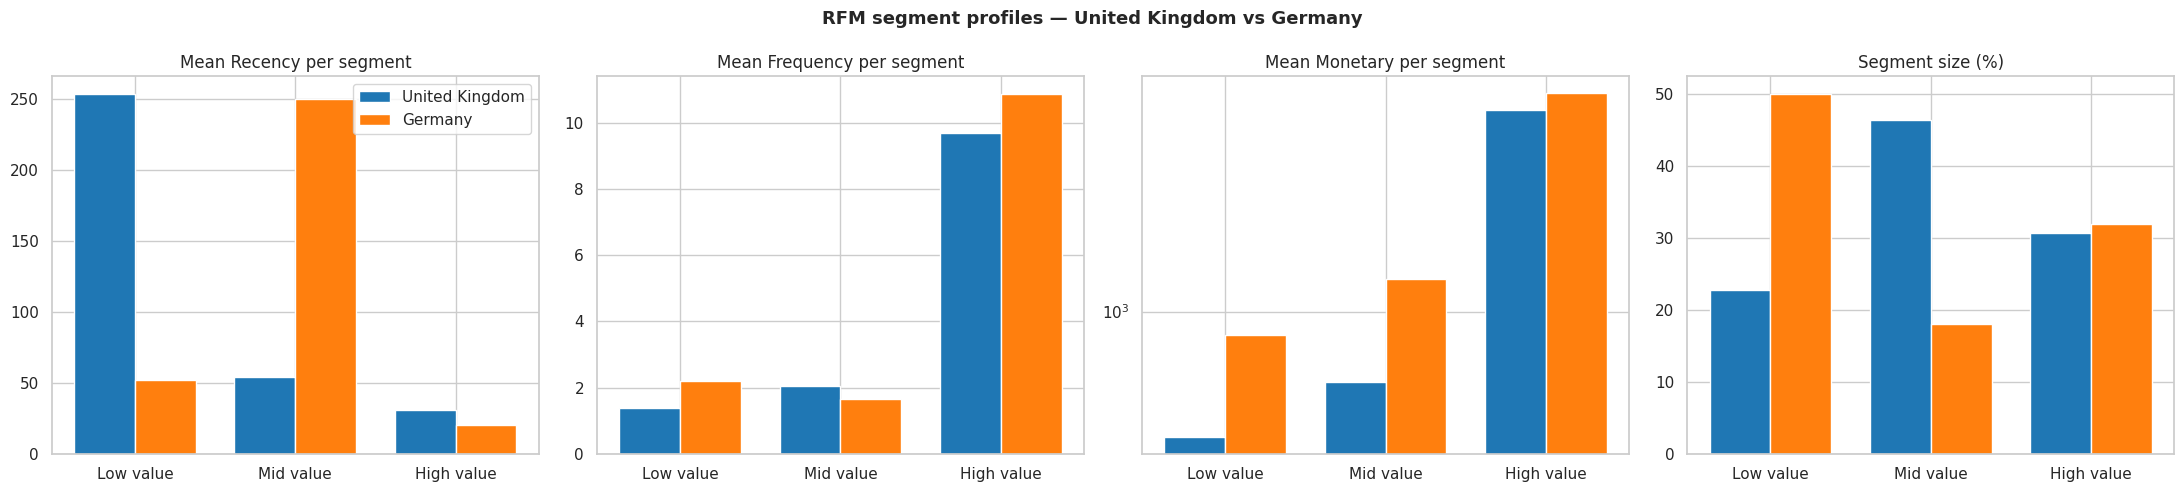


Overall medians per country:
           United Kingdom  Germany
Recency              51.0     31.0
Frequency             2.0      3.0
Monetary            652.3   1066.1


In [36]:
# Challenge 9.3 — Country segment comparison (United Kingdom vs Germany/France)
def rfm_for_country(df_tx, country, k=K_BEST):
    d = df_tx[df_tx['Country'] == country]
    r = d.groupby('CustomerID').agg(
        Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),   # same reference date for both
        Frequency=('InvoiceNo', 'nunique'),
        Monetary=('TotalPrice', 'sum'),
    ).reset_index()
    r_log = r[['Recency', 'Frequency', 'Monetary']].copy()
    r_log[log_features] = np.log1p(r_log[log_features])
    Xc = StandardScaler().fit_transform(r_log)
    km_c = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    r['Cluster'] = km_c.fit_predict(Xc)
    # Relabel clusters by mean Monetary so that segment 0 = lowest value ... k-1 = highest value
    order = r.groupby('Cluster')['Monetary'].mean().sort_values().index
    r['Segment'] = r['Cluster'].map({c: i for i, c in enumerate(order)})
    prof = r.groupby('Segment').agg(Customers=('CustomerID', 'count'), Recency=('Recency', 'mean'),
                                    Frequency=('Frequency', 'mean'), Monetary=('Monetary', 'mean'))
    prof['% customers'] = 100 * prof['Customers'] / len(r)
    return r, prof, silhouette_score(Xc, r['Cluster'])

customers_per_country = df.groupby('Country')['CustomerID'].nunique().sort_values(ascending=False)
print("Customers per country (top 5):"); print(customers_per_country.head().to_string())
other_country = 'Germany' if customers_per_country.get('Germany', 0) >= customers_per_country.get('France', 0) else 'France'

profiles, rfm_country = {}, {}
for country in ['United Kingdom', other_country]:
    rfm_country[country], profiles[country], sil_c = rfm_for_country(df, country)
    print(f"\n{country}: {len(rfm_country[country])} customers | silhouette (k={K_BEST}) = {sil_c:.3f}")
    print(profiles[country].round(1).to_string())

seg_names = {0: 'Low value', 1: 'Mid value', 2: 'High value'} if K_BEST == 3 else {i: f'Segment {i}' for i in range(K_BEST)}
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
width = 0.38
for j, feat in enumerate(['Recency', 'Frequency', 'Monetary', '% customers']):
    for i, country in enumerate(profiles):
        p = profiles[country]
        axes[j].bar(np.arange(K_BEST) + (i - 0.5) * width, p[feat], width, label=country)
    axes[j].set_xticks(range(K_BEST)); axes[j].set_xticklabels([seg_names[s] for s in range(K_BEST)])
    axes[j].set_title(f'Mean {feat} per segment' if feat != '% customers' else 'Segment size (%)')
    if feat == 'Monetary':
        axes[j].set_yscale('log')
axes[0].legend()
plt.suptitle(f'RFM segment profiles — United Kingdom vs {other_country}', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print("\nOverall medians per country:")
print(pd.DataFrame({c: rfm_country[c][['Recency', 'Frequency', 'Monetary']].median() for c in rfm_country}).round(1).to_string())

**¿Difieren los patrones de compra entre países?** Se comparó el **Reino Unido** (3 920 clientes, silueta 0.417) con **Alemania** (94 clientes, el segundo país con más clientes, silueta 0.457), ambos con K-Means k = 3.

**Advertencia sobre la gráfica:** el código ordena los segmentos de cada país por gasto medio (Monetary) y los rotula como *Low / Mid / High value*. En el Reino Unido ese orden coincide con el comportamiento: perdidos, regulares y alto valor. En Alemania **no**: su segmento de clientes perdidos (Recency ≈ 250 días) gasta más que el de clientes regulares. Por eso, en la gráfica, la barra **"Low value" de Alemania corresponde a sus clientes regulares** y la barra **"Mid value" a sus clientes perdidos**. Para comparar bien hay que emparejar los segmentos por comportamiento (sobre todo por Recency), como en la tabla siguiente:

| Segmento (por comportamiento) | País | % clientes | Recency (días) | Frequency | Monetary (£) |
|---|---|:---:|:---:|:---:|:---:|
| **Perdidos** | Reino Unido | 22.8 % | 253.0 | 1.4 | 373 |
|  | Alemania | 18.1 % | 250.0 | 1.6 | 1 295 |
| **Regulares** | Reino Unido | 46.5 % | 54.2 | 2.0 | 575 |
|  | Alemania | 50.0 % | 52.0 | 2.2 | 829 |
| **Alto valor** | Reino Unido | 30.8 % | 30.5 | 9.7 | 4 917 |
|  | Alemania | 31.9 % | 20.3 | 10.9 | 5 597 |

Medianas generales: Recency de 51 días (Reino Unido) frente a 31 (Alemania); Frequency de 2 frente a 3; Monetary de £652 frente a £1 066.

- **La estructura de los segmentos es la misma en ambos países:** perdidos, regulares y alto valor, con proporciones parecidas (≈ 20 % / ≈ 48 % / ≈ 31 %). La segmentación RFM se transfiere bien entre mercados.
- **Los niveles sí difieren:** **los clientes alemanes gastan más en todos los segmentos** y, en general, son más activos (compraron más recientemente y hacen más pedidos). Lo más llamativo: los clientes alemanes *perdidos* gastaron en promedio £1 295, más que los clientes *regulares* del Reino Unido (£575). Encaja con un mercado extranjero dominado por compradores de tipo mayorista o empresarial, frente a una larga cola de compradores pequeños y ocasionales en el mercado doméstico.
- **El segmento de alto valor también es más alto en Alemania** (£5 597 frente a £4 917 de media), así que no se puede afirmar que el Reino Unido tenga compradores top "más extremos" en promedio.

**Advertencias:**

- Con solo 94 clientes, la segmentación de Alemania es mucho menos estable: unos pocos clientes pueden mover un centroide.
- Las medias de gasto están dominadas por unas pocas cuentas grandes.

En la práctica sería preferible un único modelo global con un indicador de país, o umbrales por país, en lugar de entrenar un clustering separado para un mercado tan pequeño. Para una versión futura, los segmentos deberían rotularse según su comportamiento (por ejemplo, ordenándolos por Recency) y no solo por Monetary.

## Summary and Key Takeaways <a id='10'></a>

| Concept | Takeaway |
|---|---|
| RFM engineering | Raw transactions must be aggregated into per-entity features before clustering |
| Scaling | Always scale before K-Means or Hierarchical; GMM is less sensitive but still benefits |
| Elbow + Silhouette | Use both together — elbow finds the bend, silhouette confirms |
| Ward linkage | Default first choice for agglomerative clustering; produces balanced clusters |
| BIC/AIC | Prefer BIC for GMM; lower = better fit adjusted for complexity |
| Internal vs external | Internal metrics measure geometry; external metrics measure semantic alignment |
| ARI/NMI | Use when any ground-truth labels are available, even for a validation subset |

### Resources

- [scikit-learn clustering user guide](https://scikit-learn.org/stable/modules/clustering.html)
- [UCI Online Retail dataset](https://archive.ics.uci.edu/ml/datasets/Online+Retail)
- [UCI HAR dataset](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones)
- Kaufman & Rousseeuw (1990) — *Finding Groups in Data* (silhouette score)
- McLachlan & Basford (1988) — *Mixture Models* (GMM theory)